# DAT535 Project – Group 24: Norgespris and electricity use
## Notebook 03: Gold layer – star schema, dashboard tables and analysis

**Input:** the `silver` schema in PostgreSQL (clean, typed, daily tables from notebook 02 / stage `silver`).
**Output:** the `gold` schema in PostgreSQL – a **Kimball star schema** (dimensions + facts), **dashboard tables** (`agg_*`) that answer
the project question, a **publish log** and **check results**. The second half of this notebook *is* the dashboard: tables, plots and trend analysis.

```text
silver.* ──(Spark SQL: dimensions, facts, aggregates)──▶ gold_stage.*  ──(checks pass?)──▶ gold.*        (the published version)
                                                                         │                    └─▶ gold_previous.*  (the version before)
                                                                         └─(checks fail)──▶ gold.* untouched, run logged as "blocked"
```

This notebook implements **section 5 (Gold)** and the Gold part of **section 6 (end-to-end delivery)** of our *Data Engineering Project
Definition Guide (v3)*. Section 1 answers the guide's questions one by one; the code in sections 2–7 follows those answers.

**How it fits the repo** (same pattern as notebooks 01 and 02)
* The code cells marked as pipeline code are also in **`gold_pipeline.py`** (generated from this notebook), so GitHub Actions runs exactly
  this code: `python run_pipeline.py gold` (and `all` = `bronze` → `postgres` → `silver` → `gold`).
* Same environment as before: `.env`, `NORGESPRIS_ENV` (dev/prod → database `norgespris_dev`/`norgespris_prod`), `get_spark()` and the
  PostgreSQL settings from `bronze_to_postgres.py`.
* Tests: `tests/test_gold.py` builds the whole star schema from a few hand-made Silver rows (no database needed) and checks the results.

---
# 1. Gold design (answers to section 5 of the definition guide)

### 1.1 Which question does Gold answer?
> *Has daily electricity use per household and per inhabitant changed after Norgespris (1 October 2025), adjusted for temperature,
> and where are the changes most visible?*

**Consumers:** the group, the examiner and analysts – through the dashboard in section 8 of this notebook, or with SQL directly
on the `gold` schema (any BI tool that can read PostgreSQL works, e.g. Power BI, Metabase, Excel).

### 1.2 Why is Gold structured differently from Silver?
Silver is organised **by source** (one clean table per dataset, keys from the sources). Gold is organised **by the question**:

| | Silver | Gold |
|---|---|---|
| Shape | one table per source, natural keys (`municipality_no`, `date`) | **star schema**: facts with integer keys pointing to shared dimensions |
| Purpose | trusted, reusable data | fast, simple answers: *"kWh per household by price area after Norgespris"* = one join + one `GROUP BY` |
| Content | only what the source says | business attributes added: county name, price area, Norgespris period, heating season, heating degree days, Norgespris eligibility, monthly cap |
| Ready-made answers | – | `agg_*` tables: already aggregated and temperature-adjusted for the dashboard |

### 1.3 Kimball dimensional model

We followed Kimball's four steps: **(1) business process** = electricity consumption of Norwegian municipalities; **(2) grain** =
one municipality, one day, one customer group; **(3) dimensions** = *when, where, who* (date, municipality, price area, customer group);
**(4) facts** = the numbers measured at that grain (kWh, metering points, Norgespris meters). Temperature and population are measured at
*other* grains, so they get **their own fact tables** that share the same (*conformed*) dimensions – the dashboard combines them
("drill across") on `date_key` + `municipality_key`. That keeps every fact table **additive**: summing kWh over any dimension is always correct.

```text
                       dim_date (date_key)              dim_customer_group            dim_consumption_group
                     /      |        \          \        (customer_group_key)         (consumption_group_key)
 fact_population_yearly  fact_weather_daily  fact_consumption_daily ─┘            fact_norgespris_price_area_daily ─┘
                     \      |        /          \                                            |
                 dim_municipality (municipality_key)   dim_price_area (price_area_key) ──────┘
```

**Two group dimensions, on purpose.** Elhub's hourly consumption file has a *customer* group per metering point (`private`, `business`,
`industry`) – Silver calls it `customer_group`. Elhub's Norgespris files have a *consumption* group: the groups Norgespris covers
(`household`, `cabin`). `private` = `household` + `cabin`, but the consumption file does not say how much is which. Silver therefore splits
private kWh and meters into household and cabin with a **distribution key** (`silver.private_split_daily`, notebook 02 §4.6), and Gold stores
that split as its own fact, **`fact_private_split_daily`**, on `dim_consumption_group` – the same dimension the Norgespris facts use. So:
* `fact_consumption_daily` → `dim_customer_group` (measured: private / business / industry),
* `fact_private_split_daily` and `fact_norgespris_price_area_daily` → `dim_consumption_group` (household / cabin).

| Table | Type | Grain (one row per …) | Keys | Measures / attributes |
|---|---|---|---|---|
| `dim_date` | dimension | calendar day | `date_key` (yyyymmdd) | year, month, ISO week, weekday, weekend, season, heating season, energy year (Jul–Jun), **Norgespris period** before/after, days since start |
| `dim_municipality` | dimension | municipality (+ 1 "unknown" row) | `municipality_key` | number, name, county number + name, price area (main), `is_known` |
| `dim_customer_group` | dimension | customer group (consumption data) | `customer_group_key` | private / business / industry, **Norgespris eligible** (private) |
| `dim_consumption_group` | dimension | Norgespris consumption group | `consumption_group_key` | household / cabin, monthly cap |
| `dim_price_area` | dimension | price area NO1–NO5 (+ unknown) | `price_area_key` | name |
| `fact_consumption_daily` | fact (transaction) | municipality × day × customer group | date, municipality, customer group, price area | kWh, metering points, complete day (**measured**) |
| `fact_private_split_daily` | fact (allocated) | municipality × day × consumption group (household / cabin) | date, municipality, consumption group, price area | kWh and meters **allocated** from private with the distribution key, meters with Norgespris, meters counted, key method |
| `fact_weather_daily` | fact | municipality × day | date, municipality, price area | mean temperature, **heating degree days (HDD)**, number of stations, method |
| `fact_population_yearly` | fact (snapshot) | municipality × year (1 January) | date (1 Jan), municipality, price area | population |
| `fact_norgespris_price_area_daily` | fact | day × price area × consumption group × consumption band | date, price area, consumption group + band | kWh and meters with/without Norgespris |

**Keys.** `date_key` = `20251001` (readable, sorts like the date). `municipality_key` = the municipality number as an integer (`0301` → `301`):
stable between runs, so a saved dashboard filter keeps working. `-1` = "unknown" (Elhub code `0`, or a code that matches no SSB municipality) – kept,
so **no kWh is lost** (check G-01). **History:** municipalities are type-1 (current state): Silver already maps old (pre-2024) codes to today's
municipality, so every day is reported in today's structure.

### 1.4 Dashboard tables (`agg_*`) – the answer, pre-computed

| Table | Grain | What it is for |
|---|---|---|
| `agg_municipality_daily` | municipality × day | one wide row per municipality and day: kWh per group, population, temperature, HDD, the ratios (kWh per household, per inhabitant, …), Norgespris share |
| `agg_area_daily` | level × area × measure × day | daily **actual vs expected** (temperature-adjusted) for Norway, each price area and each county |
| `agg_norgespris_effect` | level × area × measure | **the answer**: temperature-adjusted change after Norgespris, for Norway, price areas, counties **and all municipalities**, with ranking and a reliability flag |
| `agg_monthly_trend` | level × area × measure × month | monthly trend, adjusted change per month, year-over-year change |
| `agg_norgespris_uptake_daily` | day × price area × group | how many meters and how much kWh are on Norgespris (adoption curve) |

`level` is `national`, `price_area`, `county` or `municipality` (municipality only in `agg_norgespris_effect`, to keep the daily table small).
**Measures** (all *per day*):

| Measure | Formula | Measured or allocated? |
|---|---|---|
| `kwh_per_private_meter` | private kWh ÷ private metering points | **measured** – no key involved; the most robust number |
| `kwh_per_household` | household kWh ÷ household metering points | allocated (distribution key) |
| `kwh_household_per_capita` | household kWh ÷ inhabitants (cabins left out: cabin owners live elsewhere) | allocated |
| `kwh_per_cabin` | cabin kWh ÷ cabin metering points | allocated |
| `kwh_all_per_capita` | all kWh (private + business + industry) ÷ inhabitants | measured |
| `kwh_per_business_meter` | business kWh ÷ business metering points – **not** eligible for Norgespris → our **control group** | measured |

*Industry* is kept in the tables (kWh, meters) but not used as a measure: a few very large plants dominate it, so it says little about behaviour.

### 1.5 How "adjusted for temperature" is done (and why this way)
Electricity use in Norway depends mostly on temperature (heating). A cold winter after the start would look like "Norgespris increased use".
We use **heating degree days**, the standard Norwegian method (base 17 °C): `HDD = max(0, 17 − mean temperature)`.

1. **Baseline model, before Norgespris** (2024-01-01 … 2025-09-30), separately for every area and measure:
   `daily value = a + b × HDD` – a straight line fitted with Spark SQL's `regr_intercept`, `regr_slope`, `regr_r2`.
2. **Expected value after the start:** put the *actual* temperatures after 1 October 2025 into the line → what use *would* have been
   without any change in behaviour.
3. **Adjusted change** = `Σ actual ÷ Σ expected − 1` (in %) over all days after the start. Positive = higher use than the temperature explains.
4. **Control group:** the same for business meters (no Norgespris). `adjusted_change_vs_business_pp` = household change − business change
   removes changes that hit everybody (economy, a data issue, …) – a simple *difference-in-differences*.
5. **Reliable** only if ≥ 180 days before, ≥ 28 days after and R² ≥ 0.3. Rankings use reliable rows only.

*Why not just "after vs before"?* The after-period (Oct–Nov…) and the before-period (Jan 2024–Sep 2025) contain different seasons; the raw
change (`raw_change_pct`, also stored) is therefore misleading – the dashboard shows both so the difference is visible.

### 1.6 Correctness, refresh, readiness and upstream failure (guide §5)

| Guide question | Our answer |
|---|---|
| **Correctness** – compare key values between layers | Checks G-01 … G-10 (section 6) run **inside PostgreSQL** on the new tables: kWh Gold = kWh Silver, rows, population, temperature days, unique grain, no orphan keys, upstream Silver run OK, temperature coverage, freshness. Stored in `gold.check_results` (history). |
| **Usefulness** | the dashboard in section 8 answers the question directly; every number can be traced back through the facts to Silver. |
| **Refresh** | monthly, after Elhub has published the previous month (workflow `pipeline.yml`, 5th of every month); can also be run by hand. Full rebuild every time (small data: ~1 M fact rows) – simpler and always consistent. |
| **How do consumers know it is ready?** | `gold.publish_log`: one row per run; the newest row with `status = 'published'` says which data (first/last day, Silver run) is live. Dashboards read this first. Also `_gold_summary.md` in the landing folder and in the GitHub Actions summary. |
| **Upstream incomplete / failed** | (1) `run_pipeline.py all` stops before Gold if Silver fails. (2) Gold builds in `gold_stage`; only if **all error checks pass** are the tables moved into `gold` in **one transaction**. Otherwise `gold` stays as it was and the run is logged as `blocked`. (3) The version before is kept in `gold_previous` (guide: "previous versions are kept"). |

---
# 2. Setup

### 2.1 Imports, settings and logging
* **Same building blocks as Silver:** `get_spark()` and the PostgreSQL settings come from `bronze_to_postgres.py`; `ENV`/`LANDING_DIR` from
  `bronze_pipeline.py` (both read `.env`); `SILVER_SCHEMAS` from `silver_pipeline.py` (to create an empty table if an optional Silver table is missing).
* **Settings that define the analysis** are constants at the top, so they are easy to find and the same in the notebook and the pipeline.
* Three PostgreSQL schemas are used: `gold_stage` (build), `gold` (published), `gold_previous` (the version before).

In [1]:
import os, sys                                                  # paths
sys.path.insert(0, os.path.abspath(".."))                       # repo root -> import bronze_pipeline, silver_pipeline, ...
os.environ.pop("SPARK_HOME", None)                              # use the pip PySpark, not a system Spark (e.g. /opt/spark)
# Java: if the notebook cannot find it, set JAVA_HOME in .env (read before Spark starts) - no machine-specific paths here

In [2]:
import logging                                                  # log messages (also visible in GitHub Actions)
import os                                                       # path of the run summary file
import time                                                     # elapsed time per step (performance evidence)
from datetime import date, datetime, timezone                   # run id, timestamps (UTC), the Norgespris start day
from functools import reduce                                    # combine several DataFrames into one

from pyspark import StorageLevel                                # keep reused DataFrames in memory (spill to disk if needed)
from pyspark.sql import functions as F                          # built-in column functions

from bronze_pipeline import ENV, LANDING_DIR                    # dev/prod + the landing folder (for the run summary file)
from bronze_to_postgres import get_spark, PG_URL, PG_PROPERTIES, PG_PASSWORD  # same Spark + database settings as Bronze/Silver
from silver_pipeline import SILVER_SCHEMAS                      # Silver column types (for an empty optional table)

logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(name)s - %(levelname)s - %(message)s")
logger = logging.getLogger("gold")                              # own logger name in the run log

spark = None                                                    # the SparkSession, set in run_gold() / the notebook
JDBC_READ = dict(PG_PROPERTIES, fetchsize="10000")              # stream 10 000 rows at a time (default: ALL rows into memory)

NORGESPRIS_START = date(2025, 10, 1)                            # first day with Norgespris (regjeringen.no)
HDD_BASE_C = 17.0                                               # heating degree days: base temperature 17 °C (Norwegian standard)
MIN_DAYS_BEFORE = 180                                           # a result is "reliable" with >= 180 days before the start ...
MIN_DAYS_AFTER = 28                                             # ... >= 28 days after the start ...
MIN_R2 = 0.3                                                    # ... and when temperature explains >= 30 % of the daily variation
STAGE, LIVE, PREVIOUS = "gold_stage", "gold", "gold_previous"   # build -> check -> publish; the version before is kept

2026-11-14 23:14:47,908 - bronze - INFO - Loaded ['FROST_CLIENT_ID', 'FROST_CLIENT_SECRET', 'NORGESPRIS_DEV_START_MONTH', 'NORGESPRIS_DEV_END_MONTH', 'NORGESPRIS_PROD_START_MONTH', 'NORGESPRIS_PROD_END_MONTH', 'NORGESPRIS_LANDING_ROOT', 'NORGESPRIS_PG_HOST', 'NORGESPRIS_PG_PORT', 'NORGESPRIS_PG_USER', 'NORGESPRIS_PG_PASSWORD', 'NORGESPRIS_SPARK_DRIVER_MEMORY'] from /home/ubuntu/dat535-group24/.env


### 2.2 Reference data that Gold adds
County name and main price area per municipality come from **Silver** (`COUNTIES` in notebook 02 §4.1 – the distribution key needs them
already there). Gold adds three small, hand-written lists (checked against regjeringen.no / NVE, November 2026):

* **`PRICE_AREAS`** – NO1–NO5 with their usual names.
* **`CUSTOMER_GROUPS`** – customer group (from `silver.consumption_daily`) → key, description, **Norgespris eligible** (`private` yes:
  homes and cabins; `business` and `industry` no).
* **`CONSUMPTION_GROUPS`** – Norgespris consumption group (household / cabin) → key, description, **monthly cap** (5 000 kWh for homes,
  1 000 kWh for cabins).
* A group Elhub adds later gets a key ≥ 100 automatically (in either dimension), so a new group never breaks the pipeline.

In [3]:
PRICE_AREAS = {"NO1": "Øst-Norge", "NO2": "Sør-Norge", "NO3": "Midt-Norge", "NO4": "Nord-Norge", "NO5": "Vest-Norge"}
CUSTOMER_GROUPS = {                                             # silver.consumption_daily.customer_group
    "private": (1, "Private (homes + cabins)", True),           # -> (key, description, Norgespris eligible)
    "business": (2, "Business (næring)", False),
    "industry": (3, "Industry (industri)", False),
}
CONSUMPTION_GROUPS = {                                          # consumption_group in the two Norgespris tables
    "household": (1, "Household (bolig)", 5000),                # -> (key, description, cap kWh/month)
    "cabin": (2, "Cabin / holiday home (fritidsbolig)", 1000),
}
MEASURES = {                                                    # measure name -> what it means (shown in the dashboard)
    "kwh_per_private_meter": "kWh per private metering point per day (measured)",
    "kwh_per_household": "kWh per household metering point per day (allocated)",
    "kwh_household_per_capita": "household kWh per inhabitant per day (allocated)",
    "kwh_per_cabin": "kWh per cabin metering point per day (allocated)",
    "kwh_all_per_capita": "all kWh (private + business + industry) per inhabitant per day (measured)",
    "kwh_per_business_meter": "kWh per business metering point per day (control group, no Norgespris)",
}

### 2.3 Reading and writing PostgreSQL
* `read_silver(table, by_month=True)` reads the big Silver tables with **one Spark partition per month** (one `WHERE date …` per partition),
  exactly like Silver read Bronze – the evidence for this choice is in notebook 02, section 5.3.
* `read_optional()` returns an **empty table with the Silver columns** if an optional Silver table (the two Norgespris tables) does not exist,
  so the rest of the code needs no `if`s.
* `write_stage()` writes one table to `gold_stage` and returns the row count *as PostgreSQL sees it*.
* `pg_execute()` runs statements that return nothing (`CREATE`, `ALTER`, `DROP`) in **one transaction** through the JDBC driver Spark already
  has – no extra Python package. Either all statements succeed, or none of them (`rollback`) – this is what makes publishing safe.

In [4]:
def pg_query(sql):
    """Run a SELECT inside PostgreSQL and return the result as a Spark DataFrame."""
    return spark.read.jdbc(PG_URL, f"({sql}) AS q", properties=JDBC_READ)


def pg_execute(*statements):
    """Run statements that return nothing (CREATE/ALTER/DROP) in ONE transaction, via Spark's JDBC driver."""
    jvm = spark.sparkContext._jvm                               # the Java side of Spark, where the PostgreSQL driver is loaded
    props = jvm.java.util.Properties()                          # user + password for the connection
    props.setProperty("user", PG_PROPERTIES["user"])
    props.setProperty("password", PG_PROPERTIES["password"])
    conn = jvm.org.postgresql.Driver().connect(PG_URL, props)   # the same driver Spark uses to read and write
    try:
        conn.setAutoCommit(False)                               # start a transaction: all or nothing
        statement = conn.createStatement()
        for sql in statements:
            statement.execute(sql)
        conn.commit()                                           # make all changes visible at the same moment
    except Exception:
        conn.rollback()                                         # undo everything -> nothing half-done
        raise
    finally:
        conn.close()


def silver_tables():
    """Names of the tables in the silver schema."""
    rows = pg_query("SELECT table_name FROM information_schema.tables WHERE table_schema = 'silver'").collect()
    return {r["table_name"] for r in rows}


def read_silver(table, by_month=False):
    """Read silver.<table>; with by_month=True one Spark partition per month of the 'date' column."""
    if not by_month:                                            # small table -> one partition is fine
        return spark.read.jdbc(PG_URL, f"silver.{table}", properties=JDBC_READ)
    months = [r["m"] for r in pg_query(f"SELECT DISTINCT to_char(date, 'YYYY-MM-01') AS m "
                                       f"FROM silver.{table} WHERE date IS NOT NULL").collect()]
    predicates = [f"date >= DATE '{m}' AND date < DATE '{m}' + INTERVAL '1 month'" for m in sorted(months)]
    predicates.append("date IS NULL")                           # (Silver has none, but no row may ever be lost)
    return spark.read.jdbc(PG_URL, f"silver.{table}", predicates=predicates, properties=JDBC_READ)


def empty_silver(table):
    """An empty DataFrame with the columns of silver.<table>."""
    return spark.createDataFrame([], ", ".join(f"{name} {dtype}" for name, dtype in SILVER_SCHEMAS[table]))


def read_optional(table, available, by_month=False):
    """silver.<table> if it exists, otherwise an empty table with the same columns."""
    if table in available:
        return read_silver(table, by_month)
    logger.info(f"  silver.{table} does not exist - Gold continues without it (optional)")
    return empty_silver(table)


def write_stage(df, table):
    """Replace gold_stage.<table> with df; returns the number of rows now in PostgreSQL."""
    (df.write
       .option("batchsize", 10000)                              # rows per INSERT batch
       .jdbc(PG_URL, f"{STAGE}.{table}", mode="overwrite", properties=PG_PROPERTIES))
    rows = pg_query(f"SELECT COUNT(*) AS n FROM {STAGE}.{table}").first()["n"]  # count inside the database
    logger.info(f"  {STAGE}.{table}: {rows:,} rows")
    return rows

---
# 3. Start Spark and look at the Silver input
Only in the notebook: start Spark, check which Silver tables exist and how big they are. `run_gold()` (section 7) does the same itself.

In [5]:
spark = get_spark()                                             # same session settings as notebooks 01 and 02
available = silver_tables()
print(f"Spark {spark.version} | env: {ENV} | database: {PG_URL}")
print("Silver tables:", sorted(available))
pg_query("""SELECT 'consumption_daily' AS t, COUNT(*) AS n_rows, MIN(date) AS first_day, MAX(date) AS last_day FROM silver.consumption_daily
            UNION ALL SELECT 'temperature_municipality_daily', COUNT(*), MIN(date), MAX(date) FROM silver.temperature_municipality_daily
            UNION ALL SELECT 'municipality', COUNT(*), NULL, NULL FROM silver.municipality""").show(truncate=False)

:: loading settings :: url = jar:file:/home/ubuntu/spark-env/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /home/ubuntu/.ivy2.5.2/cache
The jars for the packages stored in: /home/ubuntu/.ivy2.5.2/jars
org.postgresql#postgresql added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-b97b9e48-86a0-4de2-96c2-d8cab3d39430;1.0
	confs: [default]
	found org.postgresql#postgresql;42.7.4 in central
	found org.checkerframework#checker-qual;3.42.0 in central
:: resolution report :: resolve 190ms :: artifacts dl 5ms
	:: modules in use:
	org.checkerframework#checker-qual;3.42.0 from central in [default]
	org.postgresql#postgresql;42.7.4 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	--------------

Spark 4.3.0 | env: dev | database: jdbc:postgresql://localhost:5432/norgespris_dev
Silver tables: ['consumption_daily', 'municipality', 'norgespris_count_daily', 'norgespris_price_area_daily', 'population_yearly', 'private_split_daily', 'quality_metrics', 'rejects', 'temperature_municipality_daily', 'temperature_station_daily', 'weather_station']


+------------------------------+-------+----------+----------+
|t                             |n_rows |first_day |last_day  |
+------------------------------+-------+----------+----------+
|consumption_daily             |1124478|2024-01-01|2026-11-12|
|temperature_municipality_daily|374493 |2024-01-01|2026-11-14|
|municipality                  |357    |NULL      |NULL      |
+------------------------------+-------+----------+----------+



---
# 4. Dimensions

All Gold tables are built with **Spark SQL** (the guide: *"Spark SQL: for Gold"*): each Silver input and each Gold table is registered as a
**temporary view** with the same name as the table, so the SQL reads like the star schema (`FROM fact_consumption_daily JOIN dim_date …`).
`date_key()` is a tiny helper that writes the SQL for `yyyymmdd` keys once.

### 4.1 `dim_date`
One row per calendar day between the first and the last day found in Silver (including 1 January of every population year, so
`fact_population_yearly` can point to it). Spark generates the days itself (`sequence` + `explode`) – no calendar file needed.
* `norgespris_period` (`before`/`after`) and `days_since_norgespris` make every before/after question a simple filter.
* `is_heating_season` (October–April) and `energy_year` (July–June, e.g. `2025/26`) let us compare **the same winter months** across years.

In [6]:
def date_key(column):
    """SQL for the integer date key yyyymmdd of a date column (2025-10-01 -> 20251001)."""
    return f"CAST(date_format({column}, 'yyyyMMdd') AS INT)"


def build_dim_date(first_day, last_day):
    """One row per day from first_day to last_day, with calendar and Norgespris attributes."""
    return spark.sql(f"""
        SELECT {date_key('d')}                                             AS date_key,
               d                                                           AS date,
               year(d)                                                     AS year,
               quarter(d)                                                  AS quarter,
               month(d)                                                    AS month,
               date_format(d, 'MMMM')                                      AS month_name,
               date_format(d, 'yyyy-MM')                                   AS year_month,
               weekofyear(d)                                               AS iso_week,
               weekday(d) + 1                                              AS day_of_week,     -- 1 = Monday
               date_format(d, 'EEEE')                                      AS day_name,
               weekday(d) >= 5                                             AS is_weekend,
               CASE WHEN month(d) IN (12, 1, 2) THEN 'winter' WHEN month(d) IN (3, 4, 5) THEN 'spring'
                    WHEN month(d) IN (6, 7, 8) THEN 'summer' ELSE 'autumn' END   AS season,
               month(d) IN (10, 11, 12, 1, 2, 3, 4)                        AS is_heating_season,
               CASE WHEN month(d) >= 7                                      -- July-June, e.g. '2025/26'
                    THEN concat(CAST(year(d) AS STRING), '/', substr(CAST(year(d) + 1 AS STRING), 3, 2))
                    ELSE concat(CAST(year(d) - 1 AS STRING), '/', substr(CAST(year(d) AS STRING), 3, 2)) END AS energy_year,
               CASE WHEN d >= DATE '{NORGESPRIS_START}' THEN 'after' ELSE 'before' END AS norgespris_period,
               datediff(d, DATE '{NORGESPRIS_START}')                      AS days_since_norgespris
        FROM (SELECT explode(sequence(DATE '{first_day}', DATE '{last_day}', INTERVAL 1 DAY)) AS d)
    """)

### 4.2 `dim_municipality`, `dim_price_area`, `dim_customer_group`, `dim_consumption_group`
* **Municipality:** Silver's municipality list (with county name and main price area from Silver), plus **one "unknown" row (key −1)**.
  `price_area_key` is stored here too, so a fact row can carry the price area of its municipality.
* **Price area:** the five areas + "unknown" (−1), plus any new code that appears in the Elhub Norgespris data. Key = the digit (`NO3` → 3).
* **Customer group** (`dim_customer_group`): every `customer_group` in `silver.consumption_daily` (`private`, `business`, `industry`).
  Known groups get fixed keys 1–3 from `CUSTOMER_GROUPS`; an unexpected new group gets key 100, 101, … and `norgespris_eligible = false`.
* **Consumption group** (`dim_consumption_group`): every `consumption_group` in the two Norgespris tables; keys 1–2 from `CONSUMPTION_GROUPS`,
  a new group gets 100, 101, … Both dimensions use the same helper, `add_new_groups()`, so the rule is written once.
  The few group names are collected to Python and numbered there. *(A first version numbered them with `row_number()` over a window without
  `PARTITION BY`; Spark then warns "No Partition Defined for Window operation! Moving all data to a single partition" – harmless for 3 rows,
  but noise in the log, and the wrong pattern for big data.)*

In [7]:
def price_area_key(column):
    """'NO3' -> 3, anything else -> -1 (unknown)."""
    return F.when(column.rlike("^NO[0-9]$"), F.substring(column, 3, 1).cast("int")).otherwise(F.lit(-1))


def build_dim_municipality(municipality):
    """silver.municipality (with county name + main price area from Silver), plus one 'unknown' row (key -1)."""
    known = (municipality
             .select(F.expr("try_cast(municipality_no AS INT)").alias("municipality_key"),  # '0301' -> 301 (stable)
                     "municipality_no", "municipality_name", "county_no",
                     F.coalesce("county_name", F.lit("Unknown county")).alias("county_name"),
                     F.coalesce("price_area", F.lit("unknown")).alias("price_area"),
                     F.lit(True).alias("is_known")))
    unknown = spark.createDataFrame([(-1, "unknown", "Unknown municipality", "00", "Unknown county", "unknown", False)],
                                    known.schema)              # for Elhub code 0 and codes SSB does not know
    dim = known.unionByName(unknown)
    return dim.withColumn("price_area_key", price_area_key(F.col("price_area")))


def build_dim_price_area(norgespris):
    """NO1-NO5 + unknown, plus any other code found in the Norgespris price-area data."""
    rows = list(PRICE_AREAS.items()) + [("unknown", "Unknown price area")]
    static = spark.createDataFrame(rows, "price_area string, price_area_name string")
    extra = (norgespris.select("price_area").where("price_area IS NOT NULL").distinct()
             .join(static, "price_area", "left_anti")         # codes we did not expect
             .withColumn("price_area_name", F.col("price_area")))
    dim = static.unionByName(extra)
    return dim.select(price_area_key(F.col("price_area")).alias("price_area_key"), "price_area", "price_area_name")


def add_new_groups(known, groups, column):
    """known dimension rows + one row (key 100, 101, ...) for every value of `column` in the data that is not known."""
    known_names = {r[column] for r in known.select(column).collect()}            # 2-3 names
    found = groups.select(column).where(f"{column} IS NOT NULL").distinct().collect()  # the few names in the data
    new_names = sorted(r[column] for r in found if r[column] not in known_names)  # values we did not expect
    if not new_names:
        return known
    new = spark.createDataFrame([(100 + i, name, name) for i, name in enumerate(new_names)],   # numbered in Python:
                                f"{column}_key int, {column} string, description string")     # a handful of rows
    return known.unionByName(new, allowMissingColumns=True)     # the other columns stay NULL for a new group


def build_dim_customer_group(groups):
    """Customer groups of silver.consumption_daily: private/business/industry with fixed keys, new ones from 100."""
    known = spark.createDataFrame(
        [(key, name, text, eligible) for name, (key, text, eligible) in CUSTOMER_GROUPS.items()],
        "customer_group_key int, customer_group string, description string, norgespris_eligible boolean")
    dim = add_new_groups(known, groups, "customer_group")
    return dim.withColumn("norgespris_eligible", F.coalesce("norgespris_eligible", F.lit(False)))  # new -> not eligible


def build_dim_consumption_group(groups):
    """Norgespris consumption groups of the two Norgespris tables: household/cabin with fixed keys, new ones from 100."""
    known = spark.createDataFrame(
        [(key, name, text, cap) for name, (key, text, cap) in CONSUMPTION_GROUPS.items()],
        "consumption_group_key int, consumption_group string, description string, norgespris_cap_kwh_month int")
    return add_new_groups(known, groups, "consumption_group")

---
# 5. Facts and dashboard tables

### 5.1 The four fact tables
* **`fact_consumption_daily`** – Silver's daily consumption with dimension keys (grain: municipality × day × **customer group**). Rows with an
  unknown municipality are **kept** under key −1 (summed, because several unknown codes become one key). Only measured numbers.
* **`fact_private_split_daily`** – Silver's distribution of private into household and cabin (`silver.private_split_daily`), turned from
  columns into **one row per consumption group** (`stack`), so it uses the same `dim_consumption_group` as the Norgespris facts. With it:
  the Norgespris meters and meters counted for that group (now joined correctly: household to household, cabin to cabin).
  *(A first version joined the Norgespris counts to the customer groups – `household` never matched `private`, so all counts were empty.)* Only **additive** numbers are stored (kWh, meter counts); ratios such as kWh per meter are calculated in the `agg_*` tables,
  because a ratio cannot be summed.
* **`fact_weather_daily`** – temperature per municipality and day + **heating degree days**.
* **`fact_population_yearly`** – population on 1 January (SSB 07459), `date_key` = 1 January of that year.
* **`fact_norgespris_price_area_daily`** – Elhub's Norgespris data per price area. The consumption band (`0-3000`, `7000+`, `unknown`) is kept
  as a text column in the fact (a *degenerate dimension* – it has no attributes of its own). Elhub writes the open upper limit as 10¹², so
  limits ≥ 10⁹ are shown as `+`.

`/*+ BROADCAST(...) */` tells Spark to send the small dimension tables to every task instead of shuffling the big table (section 9 shows the plan).

In [8]:
def build_fact_consumption_daily():
    """municipality x day x customer group: kWh and meter counts with dimension keys (unknown municipality -> -1)."""
    return spark.sql(f"""
        SELECT /*+ BROADCAST(m, g) */
               {date_key('c.date')}                         AS date_key,
               COALESCE(m.municipality_key, -1)             AS municipality_key,
               g.customer_group_key,
               COALESCE(m.price_area_key, -1)               AS price_area_key,
               CAST(SUM(c.kwh) AS DECIMAL(18,3))            AS kwh,
               CAST(SUM(c.metering_points) AS INT)          AS metering_points,
               BOOL_AND(c.complete_day)                     AS complete_day
        FROM silver_consumption_daily c
        JOIN dim_customer_group g ON g.customer_group = c.customer_group
        LEFT JOIN dim_municipality m ON m.municipality_no = c.municipality_no AND c.known_municipality
        GROUP BY 1, 2, 3, 4
    """)


def build_fact_private_split_daily():
    """municipality x day x consumption group (household/cabin): private kWh and meters allocated by Silver's key."""
    return spark.sql(f"""
        WITH long AS (                                 -- household and cabin columns -> one row per consumption group
            SELECT s.municipality_no, s.date, s.key_method, x.*
            FROM silver_private_split_daily s
            LATERAL VIEW stack(2,
                'household', s.kwh_household, s.metering_points_household, s.norgespris_meters_household,
                             s.counted_meters_household, s.household_kwh_share,
                'cabin',     s.kwh_cabin, s.metering_points_cabin, s.norgespris_meters_cabin,
                             s.counted_meters_cabin, 1 - s.household_kwh_share)
                x AS consumption_group, kwh, metering_points, norgespris_metering_points, counted_metering_points,
                     share_of_private_kwh
            WHERE s.household_kwh_share IS NOT NULL)        -- no key -> nothing to allocate
        SELECT /*+ BROADCAST(m, g) */
               {date_key('l.date')}                         AS date_key,
               m.municipality_key,
               g.consumption_group_key,
               m.price_area_key,
               l.kwh, l.metering_points, l.norgespris_metering_points, l.counted_metering_points,
               ROUND(l.share_of_private_kwh, 4)             AS share_of_private_kwh,
               l.key_method
        FROM long l
        JOIN dim_municipality m ON m.municipality_no = l.municipality_no
        JOIN dim_consumption_group g ON g.consumption_group = l.consumption_group
    """)


def build_fact_weather_daily():
    """municipality x day: temperature and heating degree days."""
    return spark.sql(f"""
        SELECT /*+ BROADCAST(m) */
               {date_key('t.date')}                         AS date_key,
               m.municipality_key, m.price_area_key,
               t.mean_temp_c,
               CAST(GREATEST({HDD_BASE_C} - t.mean_temp_c, 0) AS DECIMAL(5,2)) AS hdd,   -- heating degree days
               t.n_stations,
               t.method                                     AS temperature_method
        FROM silver_temperature_municipality_daily t
        JOIN dim_municipality m ON m.municipality_no = t.municipality_no
        WHERE t.mean_temp_c IS NOT NULL
    """)


def build_fact_population_yearly():
    """municipality x year: population on 1 January."""
    return spark.sql("""
        SELECT /*+ BROADCAST(m) */
               p.year * 10000 + 101 AS date_key,           -- 1 January of that year
               m.municipality_key, m.price_area_key, p.year, p.population
        FROM silver_population_yearly p
        JOIN dim_municipality m ON m.municipality_no = p.municipality_no
    """)


def build_fact_norgespris_price_area_daily():
    """day x price area x consumption group x consumption band: kWh and meters with / without Norgespris."""
    def limit(c):                                               # 3000.000 -> '3000', NULL -> '?'
        return f"COALESCE(CAST(CAST({c} AS BIGINT) AS STRING), '?')"
    return spark.sql(f"""
        SELECT /*+ BROADCAST(a, g) */
               {date_key('n.date')}                         AS date_key,
               COALESCE(a.price_area_key, -1)               AS price_area_key,
               g.consumption_group_key,
               CASE WHEN n.eac_from_kwh IS NULL AND n.eac_to_kwh IS NULL THEN 'unknown'
                    WHEN n.eac_to_kwh IS NULL OR n.eac_to_kwh >= 1e9 THEN concat({limit('n.eac_from_kwh')}, '+')
                    ELSE concat({limit('n.eac_from_kwh')}, '-', {limit('n.eac_to_kwh')}) END AS consumption_band,
               n.eac_from_kwh, n.eac_to_kwh,
               n.kwh_norgespris, n.kwh_not_norgespris, n.kwh_total,
               n.metering_points_norgespris, n.metering_points_not_norgespris, n.metering_points_total
        FROM silver_norgespris_price_area_daily n
        JOIN dim_consumption_group g ON g.consumption_group = n.consumption_group
        LEFT JOIN dim_price_area a ON a.price_area = n.price_area
    """)

### 5.2 `agg_municipality_daily` – one wide row per municipality and day
This is the "drill across" of the four municipality facts: consumption (pivoted from the customer groups into columns), the household/cabin
split, weather and population.
* **Population of a day** = the population on 1 January of the same year; if SSB has not published that year yet, the newest earlier year
  (`MAX_BY(population, year)` over all years ≤ the day's year).
* **Ratios** use `try_divide` (Spark 4 is in ANSI mode: dividing by 0 would stop the job; `try_divide` gives NULL instead).
* Only known municipalities (key −1 has no population and no temperature).

In [9]:
def build_agg_municipality_daily():
    """municipality x day: kWh per customer group, population, temperature and the ratios the dashboard needs."""
    return spark.sql("""
        WITH c AS (                                    -- measured: customer groups side by side
            SELECT f.date_key, f.municipality_key,
                   SUM(CASE WHEN g.customer_group = 'private' THEN f.kwh END)                 AS kwh_private,
                   SUM(CASE WHEN g.customer_group = 'business' THEN f.kwh END)                AS kwh_business,
                   SUM(CASE WHEN g.customer_group = 'industry' THEN f.kwh END)                AS kwh_industry,
                   SUM(f.kwh)                                                                 AS kwh_all,
                   SUM(CASE WHEN g.customer_group = 'private' THEN f.metering_points END)     AS metering_points_private,
                   SUM(CASE WHEN g.customer_group = 'business' THEN f.metering_points END)    AS metering_points_business,
                   SUM(CASE WHEN g.customer_group = 'industry' THEN f.metering_points END)    AS metering_points_industry,
                   BOOL_AND(f.complete_day)                                                   AS complete_day
            FROM fact_consumption_daily f
            JOIN dim_customer_group g ON g.customer_group_key = f.customer_group_key
            WHERE f.municipality_key <> -1
            GROUP BY f.date_key, f.municipality_key),
        h AS (                                         -- allocated: household and cabin side by side
            SELECT f.date_key, f.municipality_key,
                   SUM(CASE WHEN g.consumption_group = 'household' THEN f.kwh END)                        AS kwh_household,
                   SUM(CASE WHEN g.consumption_group = 'cabin' THEN f.kwh END)                            AS kwh_cabin,
                   SUM(CASE WHEN g.consumption_group = 'household' THEN f.metering_points END)            AS metering_points_household,
                   SUM(CASE WHEN g.consumption_group = 'cabin' THEN f.metering_points END)                AS metering_points_cabin,
                   SUM(CASE WHEN g.consumption_group = 'household' THEN f.norgespris_metering_points END) AS norgespris_household,
                   SUM(CASE WHEN g.consumption_group = 'household' THEN f.counted_metering_points END)    AS counted_household
            FROM fact_private_split_daily f
            JOIN dim_consumption_group g ON g.consumption_group_key = f.consumption_group_key
            GROUP BY f.date_key, f.municipality_key),
        pop AS (                                       -- population for every year, from the newest year <= that year
            SELECT y.year, p.municipality_key, MAX_BY(p.population, p.year) AS population
            FROM (SELECT DISTINCT year FROM dim_date) y
            JOIN fact_population_yearly p ON p.year <= y.year
            GROUP BY y.year, p.municipality_key)
        SELECT c.municipality_key, c.date_key, d.date, d.norgespris_period,
               c.kwh_private, c.kwh_business, c.kwh_industry, c.kwh_all,
               c.metering_points_private, c.metering_points_business, c.metering_points_industry,
               h.kwh_household, h.kwh_cabin, h.metering_points_household, h.metering_points_cabin,
               p.population, w.mean_temp_c, w.hdd,
               ROUND(try_divide(CAST(c.kwh_private AS DOUBLE), c.metering_points_private), 4)     AS kwh_per_private_meter,
               ROUND(try_divide(CAST(h.kwh_household AS DOUBLE), h.metering_points_household), 4) AS kwh_per_household,
               ROUND(try_divide(CAST(h.kwh_household AS DOUBLE), p.population), 4)                AS kwh_household_per_capita,
               ROUND(try_divide(CAST(h.kwh_cabin AS DOUBLE), h.metering_points_cabin), 4)         AS kwh_per_cabin,
               ROUND(try_divide(CAST(c.kwh_all AS DOUBLE), p.population), 4)                      AS kwh_all_per_capita,
               ROUND(try_divide(CAST(c.kwh_business AS DOUBLE), c.metering_points_business), 4)   AS kwh_per_business_meter,
               h.norgespris_household, h.counted_household,
               ROUND(try_divide(CAST(h.norgespris_household AS DOUBLE), h.counted_household), 4)  AS norgespris_share_household,
               c.complete_day
        FROM c
        JOIN dim_date d ON d.date_key = c.date_key
        LEFT JOIN h ON h.date_key = c.date_key AND h.municipality_key = c.municipality_key
        LEFT JOIN fact_weather_daily w ON w.date_key = c.date_key AND w.municipality_key = c.municipality_key
        LEFT JOIN pop p ON p.municipality_key = c.municipality_key AND p.year = d.year
    """)

### 5.3 The temperature-adjusted answer: `agg_area_daily` and `agg_norgespris_effect`
Four steps, each a temporary view (so each step can be looked at on its own in the notebook); `v_model` and `v_daily` are
materialised once (`keep()`, see 5.5), because several tables read them:

1. **`v_area`** – sums per **day** for every level with `GROUPING SETS ((county), (price area), ())` = county, price area and Norway in **one**
   pass over the data, plus the municipality rows themselves. Temperature/HDD of an area = **population-weighted** average of its municipalities
   (Oslo's weather counts more than a small mountain municipality's). Only complete days with temperature and population.
2. **`v_long`** – one row per area × day × **measure** (`stack` turns the five ratio columns into rows, so steps 3–4 work for all measures at once).
3. **`v_model`** – per area and measure, the straight line `value = a + b × HDD` fitted on the days **before** Norgespris
   (`regr_intercept`, `regr_slope`, `regr_r2` are built-in Spark SQL aggregates).
4. **`v_daily`** – every day with its **expected** value `a + b × HDD`. From this: `agg_area_daily` (daily, without municipalities)
   and `agg_norgespris_effect` (one row per area and measure: adjusted change, raw change, control group, reliability, rank).

In [10]:
def keep(df, name):
    """Compute df now, keep the result and register it as view `name` (see 5.5: why localCheckpoint, not persist)."""
    df = df.localCheckpoint()                                   # materialise + cut the lineage (the plan becomes one scan)
    df.createOrReplaceTempView(name)
    return df


def build_area_views():
    """Register v_area, v_long, v_model and v_daily (see the markdown above); v_model and v_daily are materialised."""
    spark.sql("""
        CREATE OR REPLACE TEMP VIEW v_base AS
        SELECT a.*, m.municipality_no, m.municipality_name, m.county_no, m.county_name, m.price_area, p.price_area_name
        FROM agg_municipality_daily a
        JOIN dim_municipality m ON m.municipality_key = a.municipality_key
        LEFT JOIN dim_price_area p ON p.price_area_key = m.price_area_key
        WHERE a.complete_day AND a.hdd IS NOT NULL AND a.population IS NOT NULL
    """)
    sums = """SUM(kwh_private) AS kwh_private, SUM(kwh_household) AS kwh_household, SUM(kwh_cabin) AS kwh_cabin,
              SUM(kwh_business) AS kwh_business, SUM(kwh_all) AS kwh_all,
              SUM(metering_points_private) AS mp_private, SUM(metering_points_household) AS mp_household,
              SUM(metering_points_cabin) AS mp_cabin, SUM(metering_points_business) AS mp_business,
              SUM(population) AS population,
              SUM(norgespris_household) AS np_household, SUM(counted_household) AS counted_household,
              SUM(CAST(hdd AS DOUBLE) * population) / SUM(population)         AS hdd,          -- population-weighted
              SUM(CAST(mean_temp_c AS DOUBLE) * population) / SUM(population) AS mean_temp_c"""
    spark.sql(f"""
        CREATE OR REPLACE TEMP VIEW v_area AS
        SELECT CASE WHEN grouping(county_no) = 0 THEN 'county'
                    WHEN grouping(price_area) = 0 THEN 'price_area' ELSE 'national' END     AS level,
               CASE WHEN grouping(county_no) = 0 THEN county_no
                    WHEN grouping(price_area) = 0 THEN price_area ELSE 'NO' END             AS area_code,
               CASE WHEN grouping(county_no) = 0 THEN MAX(county_name)
                    WHEN grouping(price_area) = 0 THEN MAX(price_area_name) ELSE 'Norway' END AS area_name,
               date_key, {sums}
        FROM v_base
        GROUP BY date_key, GROUPING SETS ((county_no), (price_area), ())
        UNION ALL
        SELECT 'municipality', municipality_no, municipality_name, date_key, {sums}
        FROM v_base
        GROUP BY municipality_no, municipality_name, date_key
    """)
    spark.sql("""
        SELECT level, area_code, area_name, date_key, hdd, mean_temp_c,
               try_divide(CAST(np_household AS DOUBLE), counted_household) AS norgespris_share_household,
               measure, value
        FROM v_area
        LATERAL VIEW stack(6,
            'kwh_per_private_meter',    try_divide(CAST(kwh_private AS DOUBLE), mp_private),
            'kwh_per_household',        try_divide(CAST(kwh_household AS DOUBLE), mp_household),
            'kwh_household_per_capita', try_divide(CAST(kwh_household AS DOUBLE), population),
            'kwh_all_per_capita',       try_divide(CAST(kwh_all AS DOUBLE), population),
            'kwh_per_cabin',            try_divide(CAST(kwh_cabin AS DOUBLE), mp_cabin),
            'kwh_per_business_meter',   try_divide(CAST(kwh_business AS DOUBLE), mp_business)) s AS measure, value
        WHERE value IS NOT NULL
    """).createOrReplaceTempView("v_long")                    # not kept: read twice, from the kept agg_municipality_daily
    keep(spark.sql("""
        SELECT l.level, l.area_code, l.measure,
               regr_intercept(l.value, l.hdd) AS intercept,      -- a: use on a day without heating
               regr_slope(l.value, l.hdd)     AS slope,          -- b: extra use per heating degree day
               regr_r2(l.value, l.hdd)        AS r2,             -- how much of the variation temperature explains
               COUNT(*)                       AS days_before,
               AVG(l.value)                   AS avg_before,
               AVG(l.mean_temp_c)             AS mean_temp_before
        FROM v_long l JOIN dim_date d ON d.date_key = l.date_key
        WHERE d.norgespris_period = 'before'
        GROUP BY l.level, l.area_code, l.measure
    """), "v_model")
    keep(spark.sql("""
        SELECT l.*, d.date, d.norgespris_period, m.intercept + m.slope * l.hdd AS expected
        FROM v_long l
        JOIN dim_date d ON d.date_key = l.date_key
        LEFT JOIN v_model m ON m.level = l.level AND m.area_code = l.area_code AND m.measure = l.measure
    """), "v_daily")


def build_agg_area_daily():
    """Norway, price areas and counties: actual vs expected per day and measure."""
    return spark.sql("""
        SELECT level, area_code, area_name, measure, date_key, date, norgespris_period,
               ROUND(value, 4) AS value, ROUND(expected, 4) AS expected,
               ROUND(hdd, 2) AS hdd, ROUND(mean_temp_c, 2) AS mean_temp_c,
               ROUND(norgespris_share_household, 4) AS norgespris_share_household
        FROM v_daily
        WHERE level <> 'municipality'
    """)


def build_agg_norgespris_effect():
    """One row per area and measure: the temperature-adjusted change after Norgespris (the answer to the question)."""
    keep(spark.sql(f"""
        WITH after AS (
            SELECT level, area_code, measure, COUNT(*) AS days_after, AVG(value) AS avg_after,
                   AVG(expected) AS avg_expected_after, SUM(value) AS sum_after, SUM(expected) AS sum_expected_after,
                   AVG(mean_temp_c) AS mean_temp_after
            FROM v_daily WHERE norgespris_period = 'after'
            GROUP BY level, area_code, measure),
        names AS (SELECT DISTINCT level, area_code, area_name FROM v_daily),
        latest AS (                                  -- Norgespris share of household meters on the newest day
            SELECT level, area_code, MAX_BY(norgespris_share_household, date_key) AS norgespris_share_latest
            FROM v_daily WHERE norgespris_share_household IS NOT NULL GROUP BY level, area_code)
        SELECT n.level, n.area_code, n.area_name, m.measure,
               m.days_before, COALESCE(a.days_after, 0) AS days_after,
               m.intercept, m.slope, m.r2,
               m.avg_before, a.avg_after, a.avg_expected_after,
               100 * (try_divide(a.sum_after, a.sum_expected_after) - 1) AS adjusted_change_pct,
               100 * (try_divide(a.avg_after, m.avg_before) - 1)        AS raw_change_pct,
               m.mean_temp_before, a.mean_temp_after, l.norgespris_share_latest,
               COALESCE(m.days_before >= {MIN_DAYS_BEFORE} AND a.days_after >= {MIN_DAYS_AFTER}
                        AND m.r2 >= {MIN_R2}, false)                    AS reliable
        FROM v_model m
        JOIN names n ON n.level = m.level AND n.area_code = m.area_code
        LEFT JOIN after a ON a.level = m.level AND a.area_code = m.area_code AND a.measure = m.measure
        LEFT JOIN latest l ON l.level = m.level AND l.area_code = m.area_code
    """), "v_effect")
    # second step: add the business control group (self-join on the stored view) and the ranking
    return spark.sql("""
        SELECT e.level, e.area_code, e.area_name, e.measure, e.days_before, e.days_after,
               ROUND(e.intercept, 4) AS intercept, ROUND(e.slope, 4) AS slope_per_hdd, ROUND(e.r2, 3) AS r2,
               ROUND(e.avg_before, 4) AS avg_before, ROUND(e.avg_after, 4) AS avg_after,
               ROUND(e.avg_expected_after, 4) AS avg_expected_after,
               ROUND(e.adjusted_change_pct, 2) AS adjusted_change_pct,
               ROUND(e.raw_change_pct, 2) AS raw_change_pct,
               ROUND(CASE WHEN e.measure <> 'kwh_per_business_meter'
                          THEN e.adjusted_change_pct - b.adjusted_change_pct END, 2) AS adjusted_change_vs_business_pp,
               ROUND(e.mean_temp_before, 2) AS mean_temp_before, ROUND(e.mean_temp_after, 2) AS mean_temp_after,
               ROUND(e.norgespris_share_latest, 4) AS norgespris_share_latest,
               e.reliable,
               CASE WHEN e.reliable THEN ROW_NUMBER() OVER (PARTITION BY e.level, e.measure, e.reliable
                                                           ORDER BY ABS(e.adjusted_change_pct) DESC) END AS rank_abs_change
        FROM v_effect e
        LEFT JOIN v_effect b ON b.level = e.level AND b.area_code = e.area_code AND b.measure = 'kwh_per_business_meter'
    """)

### 5.4 `agg_monthly_trend` and `agg_norgespris_uptake_daily`
* **Monthly trend:** averages per month for every area and measure, the **adjusted change of each month** (is the effect growing or fading?) and
  the **year-over-year** change against the same month one year earlier, with the HDD difference next to it (a colder month explains a higher YoY).
  The previous year is found with a self-join on `add_months(month_start, -12)` – correct even if a month is missing.
* **Uptake** (per Norgespris **consumption group**): meters on Norgespris ÷ meters counted (from the municipality counts in
  `fact_private_split_daily`, summed to the municipality's main price area) and kWh on Norgespris ÷ kWh
  with or without Norgespris (from Elhub's price-area data). Rows with an empty band are left out of the kWh share automatically, because Elhub
  writes 0 kWh with/without Norgespris for them (see notebook 02, section 6).

In [11]:
def build_agg_monthly_trend():
    """Area x measure x month: averages, adjusted change of the month, year-over-year change."""
    return spark.sql("""
        WITH m AS (
            SELECT level, area_code, area_name, measure, date_format(date, 'yyyy-MM') AS year_month,
                   trunc(date, 'MM') AS month_start, COUNT(*) AS days,
                   AVG(value) AS avg_value, AVG(expected) AS avg_expected, AVG(hdd) AS avg_hdd, AVG(mean_temp_c) AS mean_temp_c,
                   100 * (try_divide(SUM(value), SUM(expected)) - 1) AS adjusted_change_pct
            FROM v_daily WHERE level <> 'municipality'
            GROUP BY level, area_code, area_name, measure, date_format(date, 'yyyy-MM'), trunc(date, 'MM'))
        SELECT m.level, m.area_code, m.area_name, m.measure, m.year_month, m.month_start, m.days,
               CASE WHEN m.month_start >= DATE '{start}' THEN 'after' ELSE 'before' END AS norgespris_period,
               ROUND(m.avg_value, 4) AS avg_value, ROUND(m.avg_expected, 4) AS avg_expected,
               ROUND(m.avg_hdd, 2) AS avg_hdd, ROUND(m.mean_temp_c, 2) AS mean_temp_c,
               ROUND(m.adjusted_change_pct, 2) AS adjusted_change_pct,
               ROUND(100 * (try_divide(m.avg_value, p.avg_value) - 1), 2) AS yoy_change_pct,
               ROUND(m.avg_hdd - p.avg_hdd, 2) AS yoy_hdd_diff
        FROM m
        LEFT JOIN m p ON p.level = m.level AND p.area_code = m.area_code AND p.measure = m.measure
                     AND p.month_start = add_months(m.month_start, -12)
    """.replace("{start}", str(NORGESPRIS_START)))


def build_agg_norgespris_uptake_daily():
    """Day x price area x consumption group (after the start): share of meters and of kWh on Norgespris."""
    return spark.sql(f"""
        WITH meters AS (                             -- Norgespris meters per municipality, summed per price area
            SELECT date_key, price_area_key, consumption_group_key,
                   SUM(norgespris_metering_points) AS norgespris_metering_points,
                   SUM(counted_metering_points) AS counted_metering_points
            FROM fact_private_split_daily
            WHERE date_key >= {NORGESPRIS_START:%Y%m%d} AND counted_metering_points IS NOT NULL
            GROUP BY date_key, price_area_key, consumption_group_key),
        kwh AS (
            SELECT date_key, price_area_key, consumption_group_key,
                   SUM(kwh_norgespris) AS kwh_norgespris, SUM(kwh_not_norgespris) AS kwh_not_norgespris
            FROM fact_norgespris_price_area_daily
            WHERE date_key >= {NORGESPRIS_START:%Y%m%d}
            GROUP BY date_key, price_area_key, consumption_group_key)
        SELECT date_key, price_area_key, consumption_group_key,
               norgespris_metering_points, counted_metering_points,
               ROUND(try_divide(CAST(norgespris_metering_points AS DOUBLE), counted_metering_points), 4) AS metering_point_share,
               kwh_norgespris, kwh_not_norgespris,
               ROUND(try_divide(CAST(kwh_norgespris AS DOUBLE), kwh_norgespris + kwh_not_norgespris), 4) AS kwh_share
        FROM meters FULL OUTER JOIN kwh USING (date_key, price_area_key, consumption_group_key)
    """)

### 5.5 Build everything in the right order
`build_gold_tables(silver)` takes the Silver DataFrames, registers them as views (`silver_<table>`), and builds the Gold tables **in dependency
order** (dimensions → facts → aggregates). Every Gold table is registered as a view with its own name right away, so the next SQL can use it.
* Spark is **lazy**: most tables are only computed when they are written (section 7). Tables that are **read by several later steps**
  (`KEEP`, and the views `v_model`, `v_daily`, `v_effect`) are computed right away with **`localCheckpoint()`** and kept in memory
  (spilling to disk if needed).
* **Why `localCheckpoint()` and not `persist()`?** – *evidence, not assumption.* Our first version used `persist()`. On the test data the
  Gold run took **148 s**, of which **83 s** were spent on `agg_norgespris_effect` (205 rows!), and the log showed a
  `java.lang.OutOfMemoryError` in a broadcast. `explain()` showed why: every view still carried its **whole lineage** back to the JDBC
  reads – the plan of the effect table had **1 576 operators**, and Spark spent its time planning and re-checking that plan. `persist()` keeps the
  *data*, but not a short *plan*. `localCheckpoint()` stores the data **and replaces the plan by a single scan** of the stored result. After the
  change: building all tables **21 s**, the effect table **0.2 s**, no memory error (section 9 shows the new, short plan).
  Trade-off: a local checkpoint lives only as long as the Spark session – fine for a batch job that rebuilds Gold every run.
* The tests call this same function with a few hand-made rows, so the tests check exactly the code that runs in production.

In [12]:
TABLES = ["dim_date", "dim_municipality", "dim_customer_group", "dim_consumption_group",      # order = build + write order
          "dim_price_area",
          "fact_consumption_daily", "fact_private_split_daily", "fact_weather_daily", "fact_population_yearly",
          "fact_norgespris_price_area_daily",
          "agg_municipality_daily", "agg_area_daily", "agg_norgespris_effect", "agg_monthly_trend",
          "agg_norgespris_uptake_daily"]
KEEP = {"dim_date", "dim_municipality", "dim_customer_group", "dim_consumption_group",         # read again by later steps
        "dim_price_area",
        "fact_consumption_daily", "agg_municipality_daily"}


def date_bounds(silver):
    """(first day, last day) over all Silver dates, incl. 1 January of every population year."""
    parts = [silver[t].select(F.min("date").alias("lo"), F.max("date").alias("hi"))
             for t in ("consumption_daily", "temperature_municipality_daily",
                       "norgespris_count_daily", "norgespris_price_area_daily")]
    parts.append(silver["population_yearly"].select(F.expr("make_date(min(year), 1, 1)").alias("lo"),
                                                    F.expr("make_date(max(year), 1, 1)").alias("hi")))
    row = reduce(lambda a, b: a.unionByName(b), parts).agg(F.min("lo").alias("lo"), F.max("hi").alias("hi")).first()
    return row["lo"], row["hi"]


def build_gold_tables(silver):
    """silver = {silver table name: DataFrame} -> {gold table name: DataFrame}, built lazily in dependency order."""
    for name, df in silver.items():
        df.createOrReplaceTempView(f"silver_{name}")             # e.g. silver_consumption_daily
    first_day, last_day = date_bounds(silver)
    if first_day is None:
        raise ValueError("Silver has no dates - is silver.consumption_daily empty?")
    consumption_groups = (silver["norgespris_count_daily"].select("consumption_group")       # Norgespris groups
                          .unionByName(silver["norgespris_price_area_daily"].select("consumption_group")))
    builders = {
        "dim_date": lambda: build_dim_date(first_day, last_day),
        "dim_municipality": lambda: build_dim_municipality(silver["municipality"]),
        "dim_customer_group": lambda: build_dim_customer_group(silver["consumption_daily"]),
        "dim_consumption_group": lambda: build_dim_consumption_group(consumption_groups),
        "dim_price_area": lambda: build_dim_price_area(silver["norgespris_price_area_daily"]),
        "fact_consumption_daily": build_fact_consumption_daily,
        "fact_private_split_daily": build_fact_private_split_daily,
        "fact_weather_daily": build_fact_weather_daily,
        "fact_population_yearly": build_fact_population_yearly,
        "fact_norgespris_price_area_daily": build_fact_norgespris_price_area_daily,
        "agg_municipality_daily": build_agg_municipality_daily,
        "agg_area_daily": build_agg_area_daily,
        "agg_norgespris_effect": build_agg_norgespris_effect,
        "agg_monthly_trend": build_agg_monthly_trend,
        "agg_norgespris_uptake_daily": build_agg_norgespris_uptake_daily,
    }
    gold = {}
    for table in TABLES:
        if table == "agg_area_daily":                           # the area views need agg_municipality_daily
            build_area_views()
        df = builders[table]()
        if table in KEEP:
            df = keep(df, table)                                # computed once now, reused by the next steps
        else:
            df.createOrReplaceTempView(table)                   # later SQL can use the table by its name
        gold[table] = df
    return gold

---
# 6. Quality checks and publishing

### 6.1 Checks (guide §5: *"comparing key values in different layers"*)
Every check is two SQL queries that run **inside PostgreSQL** on the tables just written to `gold_stage` – so we check what was really stored,
not what Spark thinks it wrote – and compare them with Silver. `equal` = the two numbers must be the same (±0.01); `at_most` = the first ≤ the second.

| Id | Severity | What is compared |
|---|---|---|
| G-01 | error | total kWh: `fact_consumption_daily` = `silver.consumption_daily` (nothing lost, nothing counted twice) |
| G-02 | error | rows with a known municipality: fact = Silver |
| G-03 | error | total population: fact = Silver |
| G-04 | error | municipality-days with temperature: fact = Silver |
| G-05 | error | kWh in `agg_municipality_daily` = known-municipality kWh in the fact |
| G-11 | error | household + cabin kWh: `fact_private_split_daily` = `silver.private_split_daily` |
| G-06 | error | the grain (primary key columns) is unique in **every** table |
| G-07 | error | **no orphan keys**: every key in a fact/agg table exists in its dimension |
| G-08 | error | upstream: the newest Silver run had 0 duplicate keys |
| G-09 | warning | municipality-days without temperature (0 expected) |
| G-10 | warning | freshness: days since the newest consumption day ≤ 45 (Elhub is about one month behind) |
| G-12 | warning | household + cabin kWh = measured **private** kWh (differs only where Silver found no distribution key) |

*Error* = Gold is **not** published. *Warning* = published, but visible in the log and the run summary.

In [13]:
PRIMARY_KEYS = {                                                # the grain of every Gold table
    "dim_date": ["date_key"],
    "dim_municipality": ["municipality_key"],
    "dim_customer_group": ["customer_group_key"],
    "dim_consumption_group": ["consumption_group_key"],
    "dim_price_area": ["price_area_key"],
    "fact_consumption_daily": ["date_key", "municipality_key", "customer_group_key"],
    "fact_private_split_daily": ["date_key", "municipality_key", "consumption_group_key"],
    "fact_weather_daily": ["date_key", "municipality_key"],
    "fact_population_yearly": ["municipality_key", "year"],
    "fact_norgespris_price_area_daily": ["date_key", "price_area_key", "consumption_group_key", "consumption_band"],
    "agg_municipality_daily": ["municipality_key", "date_key"],
    "agg_area_daily": ["level", "area_code", "measure", "date_key"],
    "agg_norgespris_effect": ["level", "area_code", "measure"],
    "agg_monthly_trend": ["level", "area_code", "measure", "year_month"],
    "agg_norgespris_uptake_daily": ["date_key", "price_area_key", "consumption_group_key"],
}
DIMENSION_OF = {"date_key": "dim_date", "municipality_key": "dim_municipality", "customer_group_key": "dim_customer_group",
                "consumption_group_key": "dim_consumption_group", "price_area_key": "dim_price_area"}
REFERENCES = {                                                  # table -> its key columns that point to a dimension
    "fact_consumption_daily": ["date_key", "municipality_key", "customer_group_key", "price_area_key"],
    "fact_private_split_daily": ["date_key", "municipality_key", "consumption_group_key", "price_area_key"],
    "fact_weather_daily": ["date_key", "municipality_key", "price_area_key"],
    "fact_population_yearly": ["date_key", "municipality_key", "price_area_key"],
    "fact_norgespris_price_area_daily": ["date_key", "price_area_key", "consumption_group_key"],
    "agg_municipality_daily": ["date_key", "municipality_key"],
    "agg_area_daily": ["date_key"],
    "agg_norgespris_uptake_daily": ["date_key", "price_area_key", "consumption_group_key"],
}
FOREIGN_KEYS = [(table, column, DIMENSION_OF[column]) for table, columns in REFERENCES.items() for column in columns]


def gold_checks(s=STAGE):
    """[(check_id, severity, description, sql for the Gold number, sql for the expected number, rule), ...]"""
    checks = [
        ("G-01", "error", "kWh: fact_consumption_daily = silver.consumption_daily",
         f"SELECT SUM(kwh) FROM {s}.fact_consumption_daily", "SELECT SUM(kwh) FROM silver.consumption_daily", "equal"),
        ("G-02", "error", "rows with a known municipality: fact = silver",
         f"SELECT COUNT(*) FROM {s}.fact_consumption_daily WHERE municipality_key <> -1",
         "SELECT COUNT(*) FROM silver.consumption_daily WHERE known_municipality", "equal"),
        ("G-03", "error", "population: fact_population_yearly = silver.population_yearly",
         f"SELECT SUM(population) FROM {s}.fact_population_yearly", "SELECT SUM(population) FROM silver.population_yearly",
         "equal"),
        ("G-04", "error", "municipality-days with temperature: fact_weather_daily = silver",
         f"SELECT COUNT(*) FROM {s}.fact_weather_daily",
         "SELECT COUNT(*) FROM silver.temperature_municipality_daily WHERE mean_temp_c IS NOT NULL", "equal"),
        ("G-05", "error", "kWh: agg_municipality_daily = known municipalities in the fact",
         f"SELECT SUM(kwh_all) FROM {s}.agg_municipality_daily",
         f"SELECT SUM(kwh) FROM {s}.fact_consumption_daily WHERE municipality_key <> -1", "equal"),
        ("G-11", "error", "kWh: fact_private_split_daily = silver.private_split_daily (household + cabin)",
         f"SELECT SUM(kwh) FROM {s}.fact_private_split_daily",
         "SELECT SUM(kwh_household + kwh_cabin) FROM silver.private_split_daily", "equal"),
    ]
    for table, columns in PRIMARY_KEYS.items():
        cols = ", ".join(columns)
        checks.append((f"G-06 {table}", "error", f"grain is unique ({cols})",
                       f"SELECT COUNT(*) FROM (SELECT 1 FROM {s}.{table} GROUP BY {cols} HAVING COUNT(*) > 1) x",
                       "SELECT 0", "equal"))
    for table, column, dim in FOREIGN_KEYS:
        checks.append((f"G-07 {table}.{column}", "error", f"every {column} exists in {dim}",
                       f"SELECT COUNT(*) FROM {s}.{table} f WHERE NOT EXISTS "
                       f"(SELECT 1 FROM {s}.{dim} d WHERE d.{column} = f.{column})", "SELECT 0", "equal"))
    checks += [
        ("G-08", "error", "upstream: newest Silver run has 0 duplicate keys",
         "SELECT COALESCE(SUM(value), 0) FROM silver.quality_metrics WHERE metric = 'duplicate_keys' "
         "AND run_id = (SELECT MAX(run_id) FROM silver.quality_metrics)", "SELECT 0", "equal"),
        ("G-09", "warning", "municipality-days without temperature",
         f"SELECT COUNT(*) FROM {s}.agg_municipality_daily WHERE hdd IS NULL", "SELECT 0", "equal"),
        ("G-12", "warning", "kWh: household + cabin = measured private kWh (private kWh without a distribution key)",
         f"SELECT SUM(kwh) FROM {s}.fact_private_split_daily",
         "SELECT SUM(kwh) FROM silver.consumption_daily WHERE customer_group = 'private' AND known_municipality", "equal"),
        ("G-10", "warning", "days since the newest consumption day (fresh data)",
         f"SELECT current_date - MAX(d.date) FROM {s}.fact_consumption_daily f "
         f"JOIN {s}.dim_date d ON d.date_key = f.date_key", "SELECT 45", "at_most"),
    ]
    return checks


def run_checks(run_id, s=STAGE):
    """Run every check in PostgreSQL; returns a list of result dicts."""
    results = []
    for check_id, severity, description, sql_gold, sql_expected, rule in gold_checks(s):
        try:
            row = pg_query(f"SELECT CAST(({sql_gold}) AS DOUBLE PRECISION) AS g, "
                           f"CAST(({sql_expected}) AS DOUBLE PRECISION) AS e").first()
            g, e = row["g"], row["e"]
            if rule == "equal":
                passed = g is not None and e is not None and abs(g - e) <= 0.01
            else:                                               # at_most
                passed = g is not None and g <= e
        except Exception as error:                              # e.g. a table is missing -> the check fails
            g, e, passed = None, None, False
            description = f"{description} (query failed: {str(error).splitlines()[0][:150]})"
        results.append({"run_id": run_id, "check_id": check_id, "severity": severity, "description": description,
                        "gold_value": g, "expected_value": e, "passed": passed})
        if not passed:
            logger.warning(f"  check {check_id} ({severity}) FAILED: {description}: gold={g}, expected={e}")
    return results

### 6.2 Constraints, publishing and the logs
* **Constraints:** after the checks pass, the primary keys and foreign keys are created in PostgreSQL. This makes the star schema visible to
  any database tool (ER diagram), gives the dashboard indexes on the keys, and protects the published tables against later wrong inserts.
* **Publish = swap in one transaction:** move the current `gold` tables to `gold_previous` (after emptying it), then move the new tables from
  `gold_stage` to `gold`. `ALTER TABLE … SET SCHEMA` only renames – it is instant, even for big tables – and PostgreSQL can do it inside a
  transaction. A dashboard therefore sees either the complete old version or the complete new version, never a mix.
* **Logs** (in schema `gold`, appended, never moved): `publish_log` (one row per run: status, Silver run, data period, failed checks) and
  `check_results` (every check of every run). Plus `_gold_summary.md` in the landing folder, which the workflows add to the GitHub run summary.

In [14]:
def add_constraints(s=STAGE):
    """Primary keys and foreign keys on the staged tables (one transaction)."""
    statements = [f"ALTER TABLE {s}.{t} ADD PRIMARY KEY ({', '.join(cols)})" for t, cols in PRIMARY_KEYS.items()]
    statements += [f"ALTER TABLE {s}.{t} ADD FOREIGN KEY ({c}) REFERENCES {s}.{dim} ({c})" for t, c, dim in FOREIGN_KEYS]
    pg_execute(*statements)


def publish(tables):
    """Swap gold_stage -> gold in one transaction; the tables that were live move to gold_previous."""
    live = {r["table_name"] for r in pg_query(
        f"SELECT table_name FROM information_schema.tables WHERE table_schema = '{LIVE}'").collect()}
    pg_execute(f"CREATE SCHEMA IF NOT EXISTS {LIVE}",
               f"DROP SCHEMA IF EXISTS {PREVIOUS} CASCADE",      # the version before the previous one is dropped
               f"CREATE SCHEMA {PREVIOUS}",
               *[f"ALTER TABLE {LIVE}.{t} SET SCHEMA {PREVIOUS}" for t in tables if t in live],
               *[f"ALTER TABLE {STAGE}.{t} SET SCHEMA {LIVE}" for t in tables])


def log_run(run_id, status, silver_run_id, first_day, last_day, checks, rows, elapsed, message=""):
    """Append one row to gold.publish_log and the check results to gold.check_results; write _gold_summary.md."""
    failed = [c["check_id"] for c in checks if not c["passed"] and c["severity"] == "error"]
    warnings = [c["check_id"] for c in checks if not c["passed"] and c["severity"] == "warning"]
    now = datetime.now(timezone.utc).isoformat(timespec="seconds")
    log = spark.createDataFrame(
        [(run_id, now, ENV, status, silver_run_id, str(first_day or ""), str(last_day or ""),
          len(checks), ", ".join(failed), ", ".join(warnings), message, float(elapsed))],
        "run_id string, logged_at string, env string, status string, silver_run_id string, first_day string, "
        "last_day string, n_checks int, failed_checks string, warning_checks string, message string, elapsed_s double")
    pg_execute(f"CREATE SCHEMA IF NOT EXISTS {LIVE}")
    log.write.jdbc(PG_URL, f"{LIVE}.publish_log", mode="append", properties=PG_PROPERTIES)
    if checks:
        (spark.createDataFrame([(c["run_id"], c["check_id"], c["severity"], c["description"], c["gold_value"],
                                 c["expected_value"], c["passed"]) for c in checks],
                               "run_id string, check_id string, severity string, description string, "
                               "gold_value double, expected_value double, passed boolean")
              .write.jdbc(PG_URL, f"{LIVE}.check_results", mode="append", properties=PG_PROPERTIES))
    lines = [f"## Gold run {run_id} ({ENV}): **{status.upper()}**", "",
             f"Data {first_day} .. {last_day} | Silver run {silver_run_id} | {elapsed:.0f}s | {message}", "",
             "| Table | Rows |", "|---|---|"] + [f"| {t} | {n:,} |" for t, n in rows.items()]
    lines += ["", "| Check | Severity | Gold | Expected | OK |", "|---|---|---|---|---|"]
    lines += [f"| {c['check_id']} | {c['severity']} | {c['gold_value']} | {c['expected_value']} | "
              f"{'✅' if c['passed'] else '❌'} |" for c in checks]
    os.makedirs(LANDING_DIR, exist_ok=True)
    with open(os.path.join(LANDING_DIR, "_gold_summary.md"), "w", encoding="utf-8") as f:
        f.write("\n".join(lines) + "\n")

---
# 7. Run Gold

### 7.1 `run_gold()` – the whole layer, as GitHub Actions runs it
1. Check that the password is set and the **required Silver tables** exist (otherwise: log `blocked`, stop – `gold` is untouched).
2. Empty `gold_stage`, read Silver (big tables by month, persisted because they are read by several steps).
3. Build all tables (section 5.5) and write them to `gold_stage`, timing each table (performance evidence, section 9).
4. Run the checks. Any **error** → log `blocked`, return `failed` (red run in GitHub Actions), `gold` stays as it was.
5. Otherwise: constraints → publish (swap) → log `published`.

In [15]:
def run_gold():
    """Build, check and publish the Gold layer; returns a summary dict (same contract as the other stages)."""
    global spark
    start_time = time.time()
    if not PG_PASSWORD or PG_PASSWORD.startswith("your-"):
        logger.error("NORGESPRIS_PG_PASSWORD is not set (in .env or as GitHub secret)")
        return {"status": "failed", "elapsed_time": 0.0}
    spark = get_spark()
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    available = silver_tables()
    required = ["municipality", "population_yearly", "consumption_daily", "temperature_municipality_daily",
                "private_split_daily"]
    missing = [t for t in required if t not in available]
    silver_run_id = None
    if "quality_metrics" in available:
        silver_run_id = pg_query("SELECT MAX(run_id) AS r FROM silver.quality_metrics").first()["r"]
    if missing:                                                 # upstream incomplete -> keep the published version
        message = f"missing Silver tables {missing} - run the silver stage first"
        logger.error(message)
        log_run(run_id, "blocked", silver_run_id, None, None, [], {}, time.time() - start_time, message)
        return {"status": "failed", "elapsed_time": time.time() - start_time, "run_id": run_id}
    logger.info(f"Gold run {run_id} (env={ENV}, Silver run {silver_run_id}) -> {PG_URL}")
    pg_execute(f"DROP SCHEMA IF EXISTS {STAGE} CASCADE", f"CREATE SCHEMA {STAGE}")   # a clean build area every run

    silver = {
        "municipality": read_silver("municipality"),
        "population_yearly": read_silver("population_yearly"),
        "consumption_daily": read_silver("consumption_daily", by_month=True).persist(StorageLevel.MEMORY_AND_DISK),
        "temperature_municipality_daily": read_silver("temperature_municipality_daily", by_month=True),
        "norgespris_count_daily": read_optional("norgespris_count_daily", available, by_month=True),
        "norgespris_price_area_daily": read_optional("norgespris_price_area_daily", available),
        "private_split_daily": read_silver("private_split_daily", by_month=True),
    }
    first_day, last_day = date_bounds(silver)
    gold = build_gold_tables(silver)
    rows, timings = {}, {}
    for table in TABLES:                                        # write in dependency order
        t0 = time.time()
        rows[table] = write_stage(gold[table], table)
        timings[table] = round(time.time() - t0, 1)

    checks = run_checks(run_id)
    failed = [c["check_id"] for c in checks if not c["passed"] and c["severity"] == "error"]
    status, message = "published", ""
    if failed:
        status, message = "blocked", f"{len(failed)} error check(s) failed - gold keeps the previous version"
    else:
        try:
            add_constraints()
            publish(TABLES)
        except Exception as error:                              # e.g. a constraint cannot be created
            status, message = "blocked", f"publishing failed: {str(error).splitlines()[0][:300]}"
    elapsed = time.time() - start_time
    log_run(run_id, status, silver_run_id, first_day, last_day, checks, rows, elapsed, message)
    spark.catalog.clearCache()                                  # free the memory of every persisted table and view
    (logger.info if status == "published" else logger.error)(
        f"Gold {status} in {elapsed:.1f}s ({len(checks)} checks, failed: {failed or 'none'}) {message}")
    return {"status": "success" if status == "published" else "failed", "elapsed_time": elapsed, "run_id": run_id,
            "published": status == "published", "rows": rows, "timings_s": timings, "failed_checks": failed}

### 7.2 Run it
In the notebook we call the same function the pipeline calls. On the full period (2024-01 → today) this takes a few minutes, most of it
writing ~1 million fact rows to PostgreSQL.

In [16]:
result = run_gold()
result

2026-11-14 23:15:10,678 - gold - INFO - Gold run 20261114T231510188052Z (env=dev, Silver run 20261114T230142682986Z) -> jdbc:postgresql://localhost:5432/norgespris_dev
26/11/14 23:15:39 WARN DAGScheduler: Broadcasting large task binary with size 1046.8 KiB
26/11/14 23:15:39 WARN DAGScheduler: Broadcasting large task binary with size 2.1 MiB
26/11/14 23:15:40 WARN DAGScheduler: Broadcasting large task binary with size 1145.5 KiB
26/11/14 23:15:42 WARN DAGScheduler: Broadcasting large task binary with size 2.4 MiB
26/11/14 23:15:43 WARN DAGScheduler: Broadcasting large task binary with size 2.3 MiB
2026-11-14 23:15:52,651 - gold - INFO -   gold_stage.dim_date: 1,049 rows       
2026-11-14 23:15:52,951 - gold - INFO -   gold_stage.dim_municipality: 358 rows
2026-11-14 23:15:53,257 - gold - INFO -   gold_stage.dim_customer_group: 3 rows
2026-11-14 23:15:53,532 - gold - INFO -   gold_stage.dim_consumption_group: 2 rows
2026-11-14 23:15:53,785 - gold - INFO -   gold_stage.dim_price_area: 6 r

{'status': 'success',
 'elapsed_time': 82.60089206695557,
 'run_id': '20261114T231510188052Z',
 'published': True,
 'rows': {'dim_date': 1049,
  'dim_municipality': 358,
  'dim_customer_group': 3,
  'dim_consumption_group': 2,
  'dim_price_area': 6,
  'fact_consumption_daily': 1124478,
  'fact_private_split_daily': 747558,
  'fact_weather_daily': 374493,
  'fact_population_yearly': 1071,
  'fact_norgespris_price_area_daily': 41668,
  'agg_municipality_daily': 373779,
  'agg_area_daily': 131922,
  'agg_norgespris_effect': 2267,
  'agg_monthly_trend': 4410,
  'agg_norgespris_uptake_daily': 4060},
 'timings_s': {'dim_date': 0.5,
  'dim_municipality': 0.3,
  'dim_customer_group': 0.3,
  'dim_consumption_group': 0.3,
  'dim_price_area': 0.3,
  'fact_consumption_daily': 5.0,
  'fact_private_split_daily': 4.9,
  'fact_weather_daily': 2.5,
  'fact_population_yearly': 0.5,
  'fact_norgespris_price_area_daily': 1.1,
  'agg_municipality_daily': 4.0,
  'agg_area_daily': 1.3,
  'agg_norgespris_effe

### 7.3 Is the new version live? (what a dashboard or analyst checks first)

In [17]:
pg_query("SELECT run_id, logged_at, env, status, first_day, last_day, silver_run_id, failed_checks, warning_checks, "
         "round(elapsed_s) AS seconds FROM gold.publish_log ORDER BY logged_at DESC LIMIT 5").show(truncate=False)
pg_query(f"SELECT check_id, severity, gold_value, expected_value, passed FROM gold.check_results "
         f"WHERE run_id = '{result['run_id']}' ORDER BY check_id").show(60, truncate=False)

+----------------------+-------------------------+---+---------+----------+----------+----------------------+-------------+--------------+-------+
|run_id                |logged_at                |env|status   |first_day |last_day  |silver_run_id         |failed_checks|warning_checks|seconds|
+----------------------+-------------------------+---+---------+----------+----------+----------------------+-------------+--------------+-------+
|20261114T231510188052Z|2026-11-14T23:16:32+00:00|dev|published|2024-01-01|2026-11-14|20261114T230142682986Z|             |              |83.0   |
|20261114T230031780336Z|2026-11-14T23:00:32+00:00|dev|blocked  |          |          |20261114T173742296371Z|             |              |0.0    |
|20261114T182839288169Z|2026-11-14T18:29:41+00:00|dev|published|2024-01-01|2026-11-14|20261114T173742296371Z|             |              |63.0   |
+----------------------+-------------------------+---+---------+----------+----------+----------------------+---------

---
# 8. Dashboard: the answer to the project question

Everything below reads **only the published `gold` tables** (as a BI tool would). The small result tables are fetched to pandas for display
and plotting – fine here, because the `agg_*` tables are already aggregated (hundreds or thousands of rows, not millions).

**Plot rules we follow** (to keep the charts honest and readable): one y-axis per chart (temperature gets its own panel instead of a second
axis), the same colour always means the same thing (blue = actual/household, orange = expected/temperature-based, aqua = cabin/control),
red/blue only for *higher/lower than expected*, thin lines, light grid, a legend whenever there are two or more series, and every chart has
a table next to it with the exact numbers.

In [18]:
import matplotlib.pyplot as plt                                 # plots (notebook only - the pipeline does not plot)
import matplotlib.dates as mdates                               # nice date axes
import numpy as np                                              # linear trend line
import pandas as pd                                             # small result tables
from IPython.display import display                             # show pandas tables nicely

BLUE, ORANGE, AQUA, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#8a8984"   # validated palette (colour-blind safe)
TEXT, GRID = "#52514e", "#e5e4e0"
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": GRID, "axes.labelcolor": TEXT, "xtick.color": TEXT,
                     "ytick.color": TEXT, "axes.titlecolor": "#0b0b0b", "axes.titlesize": 11, "axes.titleweight": "bold",
                     "font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 1.6})


def gold(sql):
    """Run a SQL query on the published Gold tables and return a pandas DataFrame."""
    return pg_query(sql).toPandas()


def mark_start(ax):
    """Vertical line + label at the first Norgespris day."""
    ax.axvline(pd.Timestamp(NORGESPRIS_START), color=GREY, linewidth=1, linestyle="--")
    ax.annotate("Norgespris starts", (pd.Timestamp(NORGESPRIS_START), 1), xycoords=("data", "axes fraction"),
                xytext=(4, -4), textcoords="offset points", va="top", color=TEXT, fontsize=8)


latest = gold("SELECT * FROM gold.publish_log WHERE status = 'published' ORDER BY logged_at DESC LIMIT 1")
assert not latest.empty, "No published Gold version yet - see gold.publish_log / gold.check_results above"
print(f"Published Gold version: run {latest.run_id[0]} | data {latest.first_day[0]} .. {latest.last_day[0]} "
      f"| Silver run {latest.silver_run_id[0]}")

/home/ubuntu/spark-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Published Gold version: run 20261114T231510188052Z | data 2024-01-01 .. 2026-11-14 | Silver run 20261114T230142682986Z


### 8.1 Headline: Norway, all measures
First a **coverage check**: how many municipality-days Gold has before and after the start, and how many are usable for the temperature model
(complete day + temperature + population). Without usable days *before* 1 October 2025 there is no baseline – the cell then stops with an
explanation of what to fix, instead of a confusing error further down.
`adjusted_change_pct` is the answer (actual vs what the temperature predicts). `raw_change_pct` is the naive before/after comparison, shown only
to make clear why the adjustment is needed. `vs_business_pp` = the change minus the business change (control group).
`kwh_per_private_meter` is **measured**; household and cabin are **allocated** from private with the distribution key (notebook 02 §4.6).

In [19]:
effect = gold("SELECT * FROM gold.agg_norgespris_effect")
MAIN = "kwh_per_household"                                      # the main measure of the dashboard

# Is there an answer at all? The model needs days BEFORE 1 Oct 2025 with consumption, temperature and population.
coverage = gold("""
    SELECT d.norgespris_period AS period, MIN(d.date) AS first_day, MAX(d.date) AS last_day,
           COUNT(*) AS municipality_days,
           COUNT(*) FILTER (WHERE a.population IS NULL) AS without_population,
           COUNT(*) FILTER (WHERE a.hdd IS NULL)        AS without_temperature,
           COUNT(*) FILTER (WHERE NOT a.complete_day)   AS incomplete_days,
           COUNT(*) FILTER (WHERE a.complete_day AND a.population IS NOT NULL AND a.hdd IS NOT NULL) AS usable_days
    FROM gold.agg_municipality_daily a JOIN gold.dim_date d USING (date_key)
    GROUP BY d.norgespris_period ORDER BY d.norgespris_period DESC""")
display(coverage.style.hide(axis="index"))
national = effect[(effect.level == "national") & (effect.measure == MAIN)]
if national.empty:                                              # stop here with an explanation instead of an IndexError later
    usable = dict(zip(coverage.period, coverage.usable_days))
    if not usable.get("before"):
        reason = ("there are no usable days BEFORE 1 October 2025. Check the period in .env on this machine "
                  "(NORGESPRIS_<ENV>_START_MONTH, e.g. 2024-01) and the rows 'without_population' / 'without_temperature' "
                  "above, then run the silver and gold stages again.")
    else:
        reason = (f"the measure '{MAIN}' has no values - is silver.private_split_daily empty or without a key "
                  "(see its key_method and the Silver metrics of private_split_daily)?")
    raise RuntimeError(f"No national result in gold.agg_norgespris_effect: {reason}")
headline = (effect[effect.level == "national"]
            .assign(meaning=lambda d: d.measure.map(MEASURES))
            [["measure", "meaning", "days_before", "days_after", "r2", "avg_before", "avg_after", "avg_expected_after",
              "adjusted_change_pct", "raw_change_pct", "adjusted_change_vs_business_pp", "reliable"]]
            .sort_values("measure"))
display(headline.style.format({"r2": "{:.2f}", "avg_before": "{:.2f}", "avg_after": "{:.2f}", "avg_expected_after": "{:.2f}",
                               "adjusted_change_pct": "{:+.1f} %", "raw_change_pct": "{:+.1f} %",
                               "adjusted_change_vs_business_pp": "{:+.1f} pp"}, na_rep="–").hide(axis="index"))

/home/ubuntu/spark-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/ubuntu/spark-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


period,first_day,last_day,municipality_days,without_population,without_temperature,incomplete_days,usable_days
before,2024-01-01,2025-09-30,228123,0,0,4,228119
after,2025-10-01,2026-11-12,145656,0,0,0,145656


measure,meaning,days_before,days_after,r2,avg_before,avg_after,avg_expected_after,adjusted_change_pct,raw_change_pct,adjusted_change_vs_business_pp,reliable
kwh_all_per_capita,all kWh (private + business + industry) per inhabitant per day (measured),639,408,0.93,63.51,66.00,64.98,+1.6 %,+3.9 %,-1.7 pp,True
kwh_household_per_capita,household kWh per inhabitant per day (allocated),639,408,0.96,18.23,19.77,19.14,+3.3 %,+8.4 %,-0.0 pp,True
kwh_per_business_meter,"kWh per business metering point per day (control group, no Norgespris)",639,408,0.81,240.62,255.10,246.95,+3.3 %,+6.0 %,–,True
kwh_per_cabin,kWh per cabin metering point per day (allocated),639,408,0.82,19.40,21.86,20.56,+6.3 %,+12.7 %,+3.0 pp,True
kwh_per_household,kWh per household metering point per day (allocated),639,408,0.96,38.47,41.56,40.40,+2.9 %,+8.0 %,-0.4 pp,True
kwh_per_private_meter,kWh per private metering point per day (measured),639,408,0.96,36.13,39.14,37.96,+3.1 %,+8.3 %,-0.2 pp,True


### 8.2 How the temperature adjustment works (Norway, kWh per household per day)
Each dot is one day. Before Norgespris (blue) use rises in a straight line with heating degree days; that line (orange) is the baseline model.
Days after the start (aqua) **above** the line mean more use than the temperature explains, **below** the line less.

/home/ubuntu/spark-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


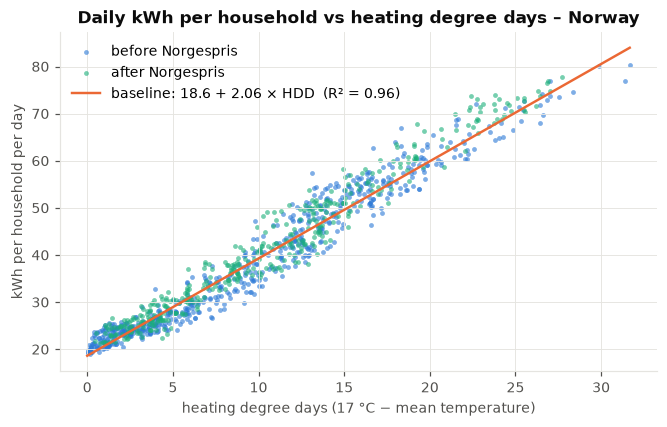

In [20]:
daily = gold(f"SELECT * FROM gold.agg_area_daily WHERE level = 'national' AND measure = '{MAIN}' ORDER BY date")
daily["date"] = pd.to_datetime(daily["date"])
model = effect[(effect.level == "national") & (effect.measure == MAIN)].iloc[0]

fig, ax = plt.subplots(figsize=(7, 4))
for period, colour, label in (("before", BLUE, "before Norgespris"), ("after", AQUA, "after Norgespris")):
    part = daily[daily.norgespris_period == period]
    ax.scatter(part.hdd, part.value, s=10, color=colour, alpha=0.6, label=label, linewidths=0)
x = np.linspace(0, daily.hdd.max(), 50)
ax.plot(x, model.intercept + model.slope_per_hdd * x, color=ORANGE, label=f"baseline: {model.intercept:.1f} + "
        f"{model.slope_per_hdd:.2f} × HDD  (R² = {model.r2:.2f})")
ax.set(title="Daily kWh per household vs heating degree days – Norway", xlabel="heating degree days (17 °C − mean temperature)",
       ylabel="kWh per household per day")
ax.legend(loc="upper left")
plt.show()

### 8.3 Time series: actual vs temperature-expected use, and the temperature behind it
Top: 7-day averages of actual and expected kWh per household (Norway). Bottom (own axis, not a second y-axis): the population-weighted
temperature. The gap between the lines after the start is the temperature-adjusted change.

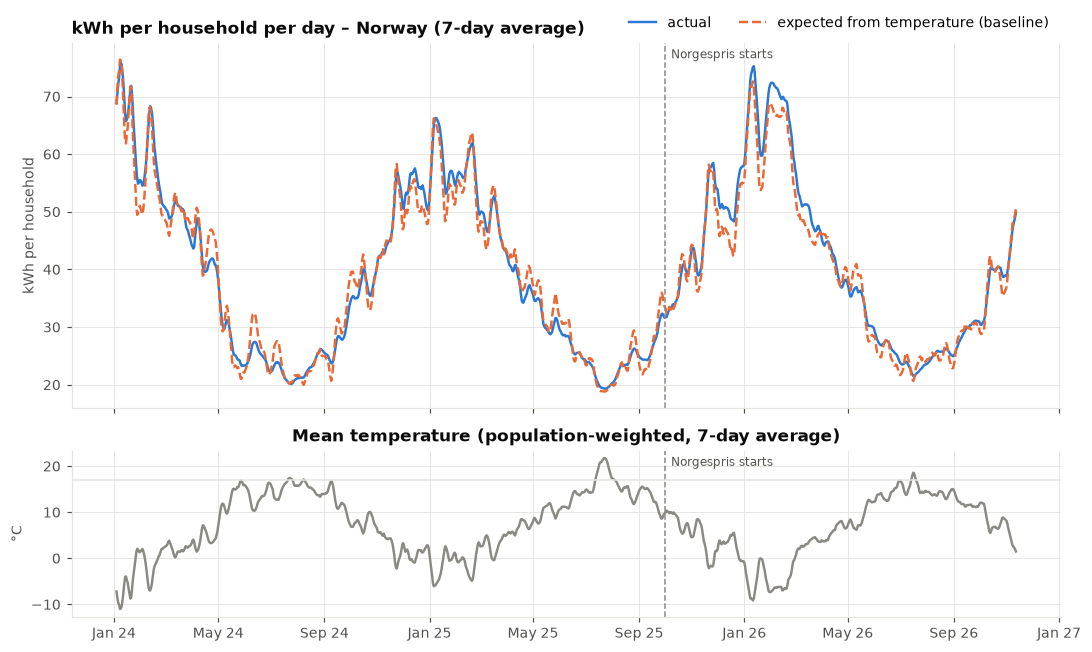

In [21]:
smooth = daily.set_index("date")[["value", "expected", "mean_temp_c"]].rolling(7, min_periods=4).mean()
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax1.plot(smooth.index, smooth.value, color=BLUE, label="actual")
ax1.plot(smooth.index, smooth.expected, color=ORANGE, linestyle="--", label="expected from temperature (baseline)")
ax1.set(ylabel="kWh per household")
ax1.set_title("kWh per household per day – Norway (7-day average)", loc="left")
ax1.legend(loc="lower right", bbox_to_anchor=(1, 1), ncol=2)  # above the plot: never on top of the lines
mark_start(ax1)
ax2.plot(smooth.index, smooth.mean_temp_c, color=GREY)
ax2.axhline(HDD_BASE_C, color=GRID, linewidth=1)
ax2.set(title="Mean temperature (population-weighted, 7-day average)", ylabel="°C")
mark_start(ax2)
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
plt.tight_layout()
plt.show()

### 8.4 Trend analysis: is the effect growing or fading?
The adjusted change for every month after the start (Norway). The line is a straight-line trend (least squares) through the monthly values:
its slope says by how many percentage points the effect changes per month. With only a few months after the start this is an indication, not
a proof – it gets stronger every month the pipeline runs.

/home/ubuntu/spark-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


year_month,days,avg_value,avg_expected,adjusted_change_pct,mean_temp_c,yoy_change_pct,yoy_hdd_diff
2025-09,30,27.74,28.17,-1.55,12.41,-1.64,-0.71
2025-10,31,37.68,38.27,-1.55,7.48,0.98,0.23
2025-11,30,49.09,47.30,3.79,3.11,1.01,-0.48
2025-12,31,52.76,48.75,8.21,2.40,-2.32,-1.31
2026-01,31,68.41,64.51,6.04,-5.23,15.39,3.62
2026-02,28,66.72,63.13,5.69,-4.56,18.11,3.71
2026-03,31,49.16,46.65,5.36,3.42,3.74,-0.26
2026-04,30,40.50,40.79,-0.72,6.26,8.77,0.78
2026-05,31,33.38,33.96,-1.69,9.57,7.40,0.41
2026-06,30,26.17,24.80,5.50,14.41,-0.55,-0.97


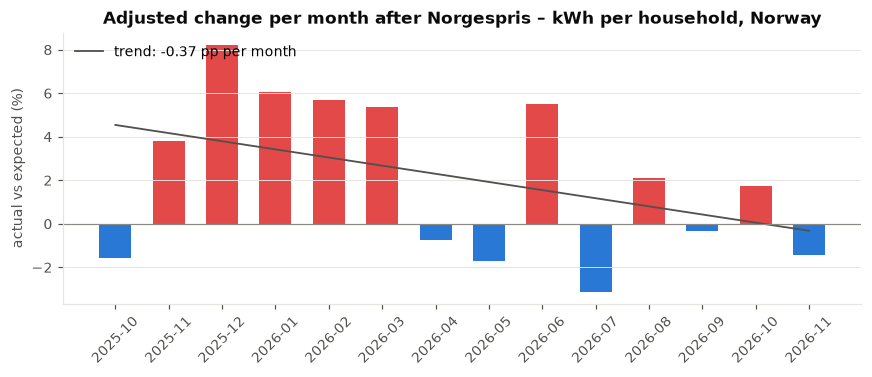

Trend: -0.37 percentage points per month over 14 months (shrinking).


In [22]:
monthly = gold(f"SELECT * FROM gold.agg_monthly_trend WHERE level = 'national' AND measure = '{MAIN}' ORDER BY month_start")
after = monthly[monthly.norgespris_period == "after"].reset_index(drop=True)
display(monthly[["year_month", "days", "avg_value", "avg_expected", "adjusted_change_pct", "mean_temp_c",
                 "yoy_change_pct", "yoy_hdd_diff"]].tail(15).style.format(precision=2, na_rep="–").hide(axis="index"))
if len(after) >= 2:
    slope, intercept = np.polyfit(after.index, after.adjusted_change_pct, 1)   # pp per month
    fig, ax = plt.subplots(figsize=(8, 3.5))
    colours = [RED if v > 0 else BLUE for v in after.adjusted_change_pct]
    ax.bar(after.index, after.adjusted_change_pct, color=colours, width=0.6)
    ax.plot(after.index, intercept + slope * after.index, color=TEXT, linewidth=1.2,
            label=f"trend: {slope:+.2f} pp per month")
    ax.set_xticks(after.index, after.year_month)                # month names under the bars
    ax.grid(axis="x", visible=False)
    ax.axhline(0, color=GREY, linewidth=0.8)
    ax.set(title="Adjusted change per month after Norgespris – kWh per household, Norway",
           ylabel="actual vs expected (%)")
    ax.legend(loc="upper left")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    print(f"Trend: {slope:+.2f} percentage points per month over {len(after)} months "
          f"({'growing' if slope > 0.1 else 'shrinking' if slope < -0.1 else 'stable'}).")
else:
    print("Fewer than 2 months after the start in this environment - no trend yet (run with a longer period).")

### 8.5 Where are the changes most visible? Price areas and counties

area_code,area_name,kwh_all_per_capita,kwh_household_per_capita,kwh_per_business_meter,kwh_per_cabin,kwh_per_household,kwh_per_private_meter,norgespris_share_latest,reliable
NO2,Sør-Norge,2.5,7.8,7.0,10.6,7.1,7.4,0.8,True
NO5,Vest-Norge,3.2,5.8,5.8,9.3,5.5,5.8,0.7,True
NO1,Øst-Norge,1.0,2.6,3.3,6.6,2.4,2.7,0.7,True
NO3,Midt-Norge,-0.2,2.1,1.2,1.7,1.0,1.1,0.6,True
NO4,Nord-Norge,2.7,-0.5,-0.5,2.0,-0.9,-0.7,0.0,True
NO1,Midt-Norge,–,–,–,–,–,–,0.7,True
NO1,Nord-Norge,–,–,–,–,–,–,0.7,True
NO1,Sør-Norge,–,–,–,–,–,–,0.7,True
NO1,Vest-Norge,–,–,–,–,–,–,0.7,True
NO2,Midt-Norge,–,–,–,–,–,–,0.8,True


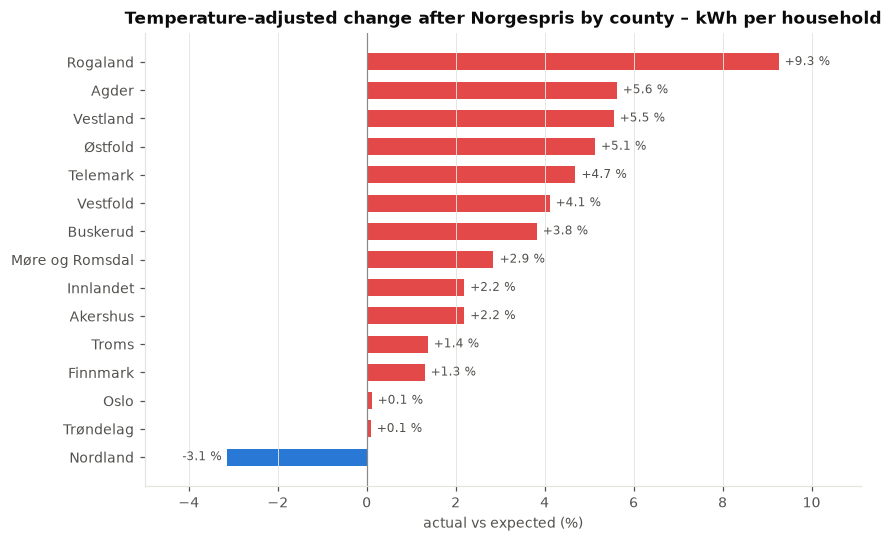

In [23]:
def area_table(level):
    """Adjusted change per area for households (per meter and per inhabitant) and the business control group."""
    d = effect[effect.level == level].pivot_table(index=["area_code", "area_name"], columns="measure",
                                                  values="adjusted_change_pct", dropna=False).reset_index()
    for m in MEASURES:                                          # a measure without any value still gets its column
        d[m] = d[m] if m in d else np.nan
    share = effect[(effect.level == level) & (effect.measure == MAIN)][["area_code", "norgespris_share_latest", "reliable"]]
    return d.merge(share, on="area_code").sort_values(MAIN, ascending=False)


price_areas = area_table("price_area")
display(price_areas.style.format(precision=1, na_rep="–").hide(axis="index"))

counties = area_table("county")
fig, ax = plt.subplots(figsize=(8, 5))
counties_sorted = counties.dropna(subset=[MAIN]).sort_values(MAIN)
ax.barh(counties_sorted.area_name, counties_sorted[MAIN],
        color=[RED if v > 0 else BLUE for v in counties_sorted[MAIN]], height=0.6)
for y, v in enumerate(counties_sorted[MAIN]):                   # direct labels: the exact value next to each bar
    ax.annotate(f"{v:+.1f} %", (v, y), xytext=(4 if v >= 0 else -4, 0), textcoords="offset points",
                ha="left" if v >= 0 else "right", va="center", color=TEXT, fontsize=8)
ax.axvline(0, color=GREY, linewidth=0.8)
ax.margins(x=0.15)                                              # room for the value labels on both sides
ax.set(title="Temperature-adjusted change after Norgespris by county – kWh per household",
       xlabel="actual vs expected (%)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 8.6 Municipalities with the largest changes
Only municipalities where the baseline model is **reliable** (≥ 180 days before, ≥ 28 after, R² ≥ 0.3). Ranked by the size of the change
(up or down). `vs_business_pp` > 0 means households changed more than business in the same municipality.

Municipalities: 357 | reliable: 356 | not reliable: 1
Largest INCREASES (actual above expected):


rank_abs_change,area_code,area_name,adjusted_change_pct,raw_change_pct,adjusted_change_vs_business_pp,r2,avg_after,avg_expected_after,norgespris_share_latest
1,1134,Suldal,+351.4 %,+369.1 %,+351.4 pp,0.91,168.3,37.3,81%
2,4619,Eidfjord,+51.1 %,+60.3 %,+41.1 pp,0.87,62.8,41.6,67%
3,1539,Rauma,+36.9 %,+41.9 %,+36.7 pp,0.91,58.0,42.4,62%
4,4617,Kvinnherad,+29.4 %,+29.9 %,+25.4 pp,0.90,46.2,35.7,78%
5,4618,Ullensvang,+26.4 %,+31.2 %,+30.0 pp,0.91,46.9,37.1,71%
6,4638,Høyanger,+25.4 %,+29.8 %,+47.0 pp,0.92,49.5,39.5,59%
7,5033,Tydal,+19.0 %,+20.4 %,-27.8 pp,0.84,55.1,46.3,63%
8,4639,Vik,+14.8 %,+16.0 %,+18.4 pp,0.88,42.8,37.3,74%
9,1816,Vevelstad,+14.5 %,+6.6 %,+5.6 pp,0.92,45.0,39.3,0%
10,1145,Bokn,+13.3 %,+19.0 %,+47.7 pp,0.91,42.7,37.7,79%


Largest DECREASES (actual below expected):


rank_abs_change,area_code,area_name,adjusted_change_pct,raw_change_pct,adjusted_change_vs_business_pp,r2,avg_after,avg_expected_after,norgespris_share_latest
18,3426,Tolga,-9.7 %,-2.7 %,-11.1 pp,0.94,50.7,56.1,71%
19,3429,Folldal,-8.7 %,-1.1 %,-10.5 pp,0.90,49.8,54.6,71%
75,4643,Årdal,-5.3 %,+6.0 %,+2.2 pp,0.91,42.4,44.8,76%
106,5542,Skjervøy,-4.3 %,+4.5 %,+0.7 pp,0.86,54.1,56.5,0%
122,3430,Os,-3.9 %,+1.1 %,-20.5 pp,0.91,51.5,53.5,73%
126,4629,Modalen,-3.8 %,+1.2 %,-6.2 pp,0.93,45.7,47.6,85%
184,1828,Nesna,-2.9 %,+1.6 %,-1.4 pp,0.92,50.2,51.7,0%
191,5510,Kvæfjord,-2.8 %,+6.3 %,+3.8 pp,0.92,51.5,53.0,0%
192,3428,Alvdal,-2.8 %,+3.3 %,-10.3 pp,0.94,52.2,53.7,78%
195,3424,Rendalen,-2.7 %,+3.7 %,+1.4 pp,0.94,42.8,44.0,71%


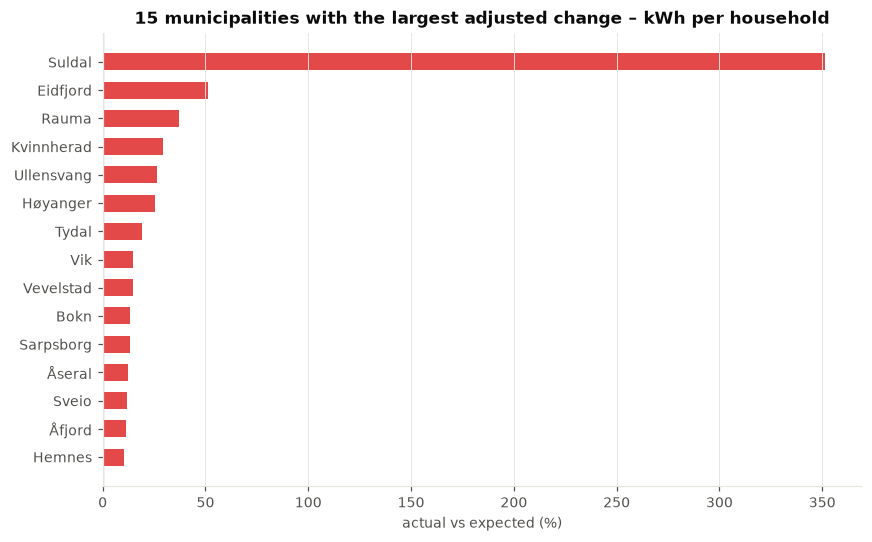

In [24]:
muni = effect[(effect.level == "municipality") & (effect.measure == MAIN)].copy()
print(f"Municipalities: {len(muni)} | reliable: {int(muni.reliable.sum())} | not reliable: {int((~muni.reliable).sum())}")
cols = ["rank_abs_change", "area_code", "area_name", "adjusted_change_pct", "raw_change_pct",
        "adjusted_change_vs_business_pp", "r2", "avg_after", "avg_expected_after", "norgespris_share_latest"]
ranked = muni[muni.reliable].sort_values("rank_abs_change")
fmt = {"adjusted_change_pct": "{:+.1f} %", "raw_change_pct": "{:+.1f} %", "adjusted_change_vs_business_pp": "{:+.1f} pp",
       "r2": "{:.2f}", "avg_after": "{:.1f}", "avg_expected_after": "{:.1f}", "norgespris_share_latest": "{:.0%}",
       "rank_abs_change": "{:.0f}"}
print("Largest INCREASES (actual above expected):")
display(ranked.sort_values("adjusted_change_pct", ascending=False)[cols].head(10).style.format(fmt, na_rep="–").hide(axis="index"))
print("Largest DECREASES (actual below expected):")
display(ranked.sort_values("adjusted_change_pct")[cols].head(10).style.format(fmt, na_rep="–").hide(axis="index"))

top = ranked.head(15).sort_values("adjusted_change_pct")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.area_name, top.adjusted_change_pct, color=[RED if v > 0 else BLUE for v in top.adjusted_change_pct], height=0.6)
ax.axvline(0, color=GREY, linewidth=0.8)
ax.set(title="15 municipalities with the largest adjusted change – kWh per household", xlabel="actual vs expected (%)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 8.7 Does a higher Norgespris share go together with a larger change?
Each dot is a municipality (reliable only): x = share of household meters with Norgespris on the newest day, y = adjusted change.
A clear upward slope would support "Norgespris customers use more"; no slope means the change is not explained by who chose Norgespris.
This is a **correlation**, not proof of cause.

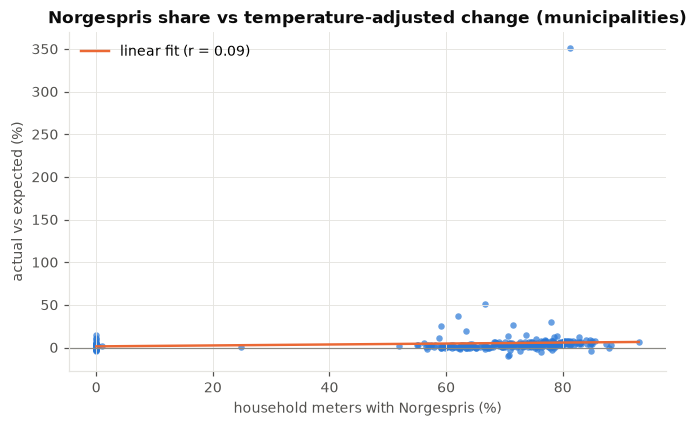

Correlation r = 0.09 over 356 municipalities.


In [25]:
sc = ranked.dropna(subset=["norgespris_share_latest", "adjusted_change_pct"])
if len(sc) >= 3:
    r = np.corrcoef(sc.norgespris_share_latest, sc.adjusted_change_pct)[0, 1]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.scatter(sc.norgespris_share_latest * 100, sc.adjusted_change_pct, s=18, color=BLUE, alpha=0.7, linewidths=0)
    b, a = np.polyfit(sc.norgespris_share_latest * 100, sc.adjusted_change_pct, 1)
    xs = np.linspace(sc.norgespris_share_latest.min() * 100, sc.norgespris_share_latest.max() * 100, 20)
    ax.plot(xs, a + b * xs, color=ORANGE, label=f"linear fit (r = {r:.2f})")
    ax.axhline(0, color=GREY, linewidth=0.8)
    ax.set(title="Norgespris share vs temperature-adjusted change (municipalities)",
           xlabel="household meters with Norgespris (%)", ylabel="actual vs expected (%)")
    ax.ticklabel_format(useOffset=False)                        # plain numbers on the axes
    ax.legend(loc="upper left")
    plt.show()
    print(f"Correlation r = {r:.2f} over {len(sc)} municipalities.")
else:
    print("Not enough reliable municipalities with a Norgespris share in this environment.")

### 8.8 Adoption: how many have chosen Norgespris?
Share of household meters with Norgespris per price area (from Elhub's municipality counts) and share of household kWh on Norgespris
(from Elhub's price-area data), as 7-day averages. Two separate charts, because they are two different measures; one fixed colour per
price area in both.

/home/ubuntu/spark-env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


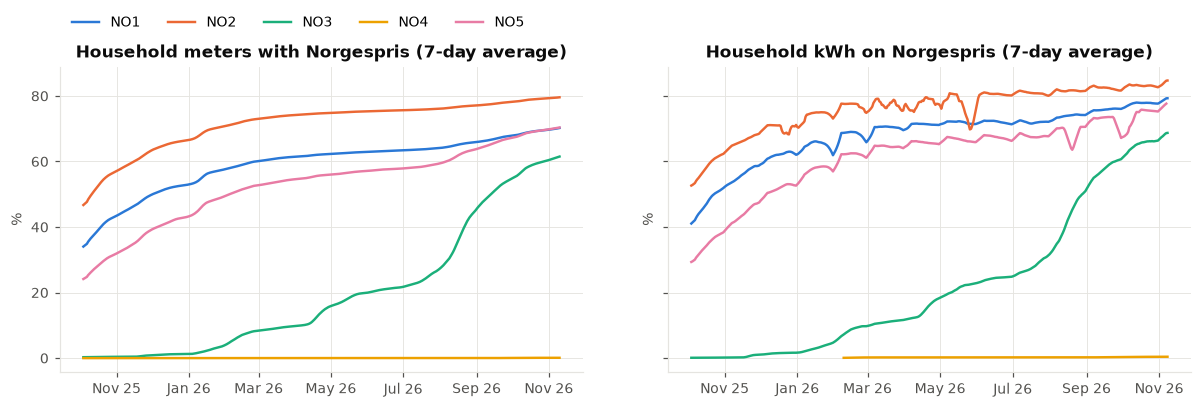

price_area,date,metering_point_share,kwh_share
NO4,2026-11-10 00:00:00,0.1%,–
NO1,2026-11-10 00:00:00,70.5%,–
NO2,2026-11-10 00:00:00,79.8%,–
NO3,2026-11-10 00:00:00,62.1%,–
NO5,2026-11-10 00:00:00,70.6%,–


In [26]:
uptake = gold("""
    SELECT d.date, p.price_area, g.consumption_group, u.metering_point_share, u.kwh_share
    FROM gold.agg_norgespris_uptake_daily u
    JOIN gold.dim_date d USING (date_key)
    JOIN gold.dim_price_area p USING (price_area_key)
    JOIN gold.dim_consumption_group g USING (consumption_group_key)
    WHERE g.consumption_group = 'household' AND p.price_area <> 'unknown'
    ORDER BY d.date""")
uptake["date"] = pd.to_datetime(uptake["date"])
AREA_COLOURS = dict(zip(sorted(PRICE_AREAS), [BLUE, ORANGE, AQUA, "#eda100", "#e87ba4"]))   # fixed colour per price area
if uptake.empty:
    print("No Norgespris data in this environment.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for ax, column, title in ((axes[0], "metering_point_share", "Household meters with Norgespris"),
                              (axes[1], "kwh_share", "Household kWh on Norgespris")):
        for area, part in uptake.dropna(subset=[column]).groupby("price_area"):
            weekly = part.set_index("date")[column].rolling(7, min_periods=4).mean() * 100   # 7-day average
            ax.plot(weekly.index, weekly, color=AREA_COLOURS.get(area, GREY), label=area)
        ax.set(title=f"{title} (7-day average)", ylabel="%")
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
    axes[0].legend(loc="lower left", bbox_to_anchor=(0, 1.08), ncol=5)   # one legend for both panels, above them
    plt.tight_layout()
    plt.show()
    newest = uptake.sort_values("date").groupby("price_area").tail(1)[["price_area", "date", "metering_point_share", "kwh_share"]]
    display(newest.style.format({"metering_point_share": "{:.1%}", "kwh_share": "{:.1%}"}, na_rep="–").hide(axis="index"))

### 8.9 The answer in words
Generated from the published numbers, so it is always up to date with the newest run.

In [27]:
def describe(measure, level="national", code="NO"):
    row = effect[(effect.level == level) & (effect.area_code == code) & (effect.measure == measure)]
    return None if row.empty else row.iloc[0]


h, c, b = describe("kwh_per_household"), describe("kwh_household_per_capita"), describe("kwh_per_business_meter")
pm = describe("kwh_per_private_meter")
if h is None or pd.isna(h.adjusted_change_pct):
    print("Not enough data before AND after 1 October 2025 in this environment to answer the question.")
else:
    direction = "higher" if h.adjusted_change_pct > 0 else "lower"
    print(f"After Norgespris started, daily electricity use per household (allocated from private) in Norway was {abs(h.adjusted_change_pct):.1f} % "
          f"{direction} than the temperature alone predicts ({h.avg_after:.1f} vs {h.avg_expected_after:.1f} kWh per day, "
          f"{h.days_after} days, baseline R² {h.r2:.2f}).")
    if pm is not None and not pd.isna(pm.adjusted_change_pct):
        print(f"Measured directly per private meter (homes + cabins, no distribution key): {pm.adjusted_change_pct:+.1f} %.")
    if c is not None and not pd.isna(c.adjusted_change_pct):
        print(f"Per inhabitant (household kWh / population): {c.adjusted_change_pct:+.1f} %.")
    if b is not None and not pd.isna(b.adjusted_change_pct):
        print(f"Business meters (no Norgespris) changed {b.adjusted_change_pct:+.1f} %, so the household change relative to the "
              f"control group is {h.adjusted_change_vs_business_pp:+.1f} percentage points.")
    if not price_areas.empty:
        top_area = price_areas.iloc[0]
        print(f"Largest change by price area: {top_area.area_code} {top_area.area_name} ({top_area[MAIN]:+.1f} %).")
    if not ranked.empty:
        m = ranked.iloc[0]
        print(f"Largest change by municipality (reliable models only): {m.area_name} ({m.adjusted_change_pct:+.1f} %).")
    print("Not reliable" if not h.reliable else "Reliable", "by our rule (>= 180 days before, >= 28 after, R² >= 0.3).")

After Norgespris started, daily electricity use per household (allocated from private) in Norway was 2.9 % higher than the temperature alone predicts (41.6 vs 40.4 kWh per day, 408 days, baseline R² 0.96).
Measured directly per private meter (homes + cabins, no distribution key): +3.1 %.
Per inhabitant (household kWh / population): +3.3 %.
Business meters (no Norgespris) changed +3.3 %, so the household change relative to the control group is -0.4 percentage points.
Largest change by price area: NO2 Sør-Norge (+7.1 %).
Largest change by municipality (reliable models only): Suldal (+351.4 %).
Reliable by our rule (>= 180 days before, >= 28 after, R² >= 0.3).


---
# 9. Performance evidence (guide §4/§7: *"tuning justified by evidence"*)

1. **Time per table** – from `run_gold()`: shows where the time goes. With `localCheckpoint()` the expensive work happens while building
   (section 5.5), so the write times are mostly JDBC (sending rows to PostgreSQL). The biggest tables (`fact_consumption_daily`,
   `agg_area_daily`, `agg_municipality_daily`) dominate.
2. **The physical plan of `fact_consumption_daily`** – the dimensions are joined with `BroadcastHashJoin` (no shuffle of the big table);
   the only big shuffle is the join with the Norgespris meter counts (both sides are large) and the `GROUP BY`.
3. **The plan of `agg_norgespris_effect` after `localCheckpoint()`** – it starts from `Scan ExistingRDD` (the stored `v_effect`) instead of
   ~1 600 operators back to the JDBC reads (section 5.5).

| Version | Whole Gold run (test data) | `agg_norgespris_effect` | Plan operators of the effect table |
|---|---|---|---|
| `persist()` (first version) | 148 s + `OutOfMemoryError` in the log | 83 s | 1 576 |
| `localCheckpoint()` (now) | see `result["elapsed_time"]` | see the table below | see the count below |

**Memory (RAM).** On a small Ubuntu machine the first real run was stopped by Linux (`Out of memory: Killed process … (java)`). We measured
the peak RAM of Spark's Java process during a whole Gold run with test data of the **real size** (360 municipalities, 1 046 days, 1.1 M
consumption rows), sampling `ps` every second:

| `spark.driver.memory` (Java heap) | intermediate tables kept | Peak RAM of the Java process | Gold run |
|---|---|---|---|
| 2g (the default) | in memory | 2.54 GB | 93 s |
| **1g** | in memory | **1.51 GB** | 95 s |
| 1g | on disk (`DISK_ONLY`) | 1.72 GB | 97 s |

* The heap size decides the RAM; Gold's data fits easily in 1g (Spark spills to disk when it needs more), and it is **not slower**.
* Keeping the intermediate tables on disk did **not** help → not used (another assumption the measurement disproved).
* The real problem was **several Spark processes at once**: every open notebook kernel keeps its own Java process alive. Hence the
  `spark.stop()` cell at the end of every notebook, and the setting `NORGESPRIS_SPARK_DRIVER_MEMORY` in `.env` (default `2g`; use `1g` on a
  machine with ≤ 8 GB RAM).

In [28]:
print(pd.Series(result.get("timings_s", {}), name="write seconds").sort_values(ascending=False).to_string())
print(f"\nWhole Gold run: {result['elapsed_time']:.0f} s")

fact_consumption_daily              5.0
fact_private_split_daily            4.9
agg_municipality_daily              4.0
fact_weather_daily                  2.5
agg_norgespris_uptake_daily         1.9
agg_monthly_trend                   1.8
agg_area_daily                      1.3
fact_norgespris_price_area_daily    1.1
agg_norgespris_effect               0.8
dim_date                            0.5
fact_population_yearly              0.5
dim_consumption_group               0.3
dim_price_area                      0.3
dim_municipality                    0.3
dim_customer_group                  0.3

Whole Gold run: 83 s


In [29]:
build_fact_consumption_daily().explain(mode="formatted")       # look for BroadcastHashJoin on the dimensions

== Physical Plan ==
AdaptiveSparkPlan (17)
+- HashAggregate (16)
   +- Exchange (15)
      +- HashAggregate (14)
         +- Project (13)
            +- BroadcastHashJoin LeftOuter BuildRight (12)
               :- Project (7)
               :  +- BroadcastHashJoin Inner BuildRight (6)
               :     :- Scan JDBCRelation(silver.consumption_daily) [numPartitions=36]  (1)
               :     +- BroadcastExchange (5)
               :        +- Project (4)
               :           +- Filter (3)
               :              +- Scan ExistingRDD (2)
               +- BroadcastExchange (11)
                  +- Project (10)
                     +- Filter (9)
                        +- Scan ExistingRDD (8)


(1) Scan JDBCRelation(silver.consumption_daily) [numPartitions=36] 
Output [7]: [municipality_no#29, date#30, customer_group#31, kwh#32, metering_points#33, complete_day#35, known_municipality#36]
PushedFilters: [*IsNotNull(customer_group)]
ReadSchema: struct<municipality_no:strin

In [30]:
plan = spark.table("agg_norgespris_effect")._jdf.queryExecution().executedPlan().toString()
print(f"Operators in the physical plan of agg_norgespris_effect: {plan.count(chr(10)) + 1}")
spark.table("agg_norgespris_effect").explain()                  # starts from 'Scan ExistingRDD' = the stored v_effect

Operators in the physical plan of agg_norgespris_effect: 16
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [level#4153, area_code#4154, area_name#4155, measure#4179, days_before#4183L, days_after#4142L, intercept#4245, slope_per_hdd#4246, r2#4247, avg_before#4248, avg_after#4249, avg_expected_after#4250, adjusted_change_pct#4251, raw_change_pct#4252, adjusted_change_vs_business_pp#4253, mean_temp_before#4254, mean_temp_after#4255, norgespris_share_latest#4256, reliable#4145, CASE WHEN reliable#4145 THEN _we0#4278 END AS rank_abs_change#4257]
   +- Window [row_number() windowspecdefinition(level#4153, measure#4179, reliable#4145, _w0#4277 DESC NULLS LAST, specifiedwindowframe(RowFrame, unboundedpreceding$(), currentrow$())) AS _we0#4278], [level#4153, measure#4179, reliable#4145], [_w0#4277 DESC NULLS LAST]
      +- Sort [level#4153 ASC NULLS FIRST, measure#4179 ASC NULLS FIRST, reliable#4145 ASC NULLS FIRST, _w0#4277 DESC NULLS LAST], false, 0
         +- Exchange h

---
# 10. Findings, assumptions, risks and improvements (guide §6)

### 10.1 What we checked and found while building Gold
| # | Topic | Status |
|---|---|---|
| 1 | **The baseline period shrinks** – Elhub's API serves only ~3 rolling years and Silver is rebuilt from it (notebook 02, §6 #1). From about November 2026 Elhub drops 2023-11, then 2024 month by month, so the *before* period (and the model) slowly changes. | ⚠️ **Urgent before spring 2027:** keep old days in Silver (append missing dates instead of overwrite), or freeze the baseline (store `v_model` once). Today: 21 months before, enough. |
| 0 | **Customer groups ≠ Norgespris groups.** Consumption has `private` / `business` / `industry`; Norgespris has `household` / `cabin`. Our first version assumed the same names → no household values and empty Norgespris counts (the dashboard stopped with an `IndexError`). | ✅ Silver distribution key (notebook 02 §4.6) + `fact_private_split_daily`. ⚠️ Household and cabin are **allocated**: the key uses the municipality's meter mix and the price area's use per meter, so a household-only change *inside one municipality* cannot be seen. Read `kwh_per_private_meter` (measured) next to `kwh_per_household`. |
| 2 | **Municipality → price area** is approximate (main price area of the county). | ⚠️ Known limitation, documented in `COUNTIES` (notebook 02 §4.1). Improvement: a municipality-level list from NVE/Elhub as a reference file in Bronze. |
| 3 | **Population** is 1 January; people with a cabin elsewhere are not counted where the cabin is. | ✅ Per-inhabitant measures use **household** kWh (and `kwh_all_per_capita` all kWh); cabin use is reported per cabin meter, not per inhabitant. |
| 4 | **Temperature model** is a straight line on HDD; it ignores daylight, holidays, weekends and price changes. | ⚠️ Simple on purpose; R² is stored and shown. Improvement: add weekday/holiday terms or use a model per season. |
| 5 | **Other things changed at the same time** (spot prices, electric cars, heat pumps, the economy). | ⚠️ The business control group (`…_vs_business_pp`) removes changes that hit everybody, not changes specific to households. We call it *change after Norgespris*, not *effect of Norgespris*. |
| 6 | Norgespris uptake by price area uses municipality counts mapped to the main price area; the kWh share uses Elhub's own price-area data. | ✅ Both shown separately; the small difference between them comes from finding 2. |
| 7 | Empty consumption band rows in the Norgespris price-area data (notebook 02, §6). | ✅ Kept in the fact as band `unknown`; left out of the kWh share automatically (0 kWh with/without). |
| 8 | Unknown municipalities (Elhub code 0 / codes SSB does not know). | ✅ Kept under key −1, so national kWh totals reconcile exactly with Silver (G-01); not used for per-capita numbers. |

### 10.2 End-to-end delivery (guide §6) – where each point is covered
| Guide point | How |
|---|---|
| Reproducibility | the repo + README: clone, `cp env.example .env`, `scripts/init_postgres.sql`, `bash scripts/setup_env.sh`, `python run_pipeline.py all`. Gold creates its schemas `gold_stage`/`gold_previous` itself. |
| Environments | `NORGESPRIS_ENV=dev/prod` → separate landing folders and databases; Gold uses the same switch. |
| Automation | workflows: **lint** (`ruff`, syntax errors and undefined names) and **pytest** (bronze, postgres, silver, **gold** tests) before the pipeline; any failure stops the run. |
| Scheduling | `pipeline.yml`: monthly (5th, 06:00 UTC) on the self-hosted runner; the dev workflow on every push to `dev_branch`; prod on `main` (stage `gold` can also be run alone). |
| Monitoring | run log; `silver.quality_metrics` + `silver.rejects`; `gold.publish_log` + `gold.check_results`; `_gold_summary.md` added to the GitHub Actions run summary and uploaded as an artifact. |
| Assumptions / risks / trade-offs | section 1 (method) and 10.1 above. Main trade-off: **full rebuild** every month (simple, consistent, ~minutes) instead of incremental loading. |

---
# 11. How to run

| Where | Command |
|---|---|
| Notebook | run notebooks 01 and 02 (or the stages `bronze`, `postgres`, `silver`) first, then all cells here |
| Terminal | `python run_pipeline.py gold` (only Gold) or `python run_pipeline.py all` (bronze → postgres → silver → gold) |
| Tests | `pytest -q tests/` |
| GitHub Actions | `pipeline.yml` (monthly) and the dev/prod workflows run `all`; the prod workflow can run `gold` alone |
| Little RAM (≤ 8 GB)? | `NORGESPRIS_SPARK_DRIVER_MEMORY=1g` in `.env`, and run **one** notebook with Spark at a time (section 12) |
| Meaningful results in **dev** | the dev period must include months before *and* after October 2025, e.g. `NORGESPRIS_DEV_START_MONTH=2025-01` and `NORGESPRIS_DEV_END_MONTH=` (empty = up to now) |

Check the result in `psql`:
```sql
SELECT status, first_day, last_day, failed_checks FROM gold.publish_log ORDER BY logged_at DESC LIMIT 3;
SELECT measure, adjusted_change_pct, adjusted_change_vs_business_pp, reliable FROM gold.agg_norgespris_effect WHERE level = 'national';
```

---
# 12. Free the memory when you are done
Spark runs in its own Java process, and that process lives as long as this notebook's kernel – **even when you have moved on to another
notebook**. Each open notebook with Spark holds 1.5–2.5 GB of RAM (section 9). On a machine with little memory, several open notebooks make
Linux kill processes (`Out of memory: Killed process … (java)` in `dmesg`). So: stop Spark here before you start another notebook.

In [31]:
spark.stop()                                                    # ends Spark's Java process and frees its memory
print("Spark stopped - re-run section 2 and 3 to start it again")

Spark stopped - re-run section 2 and 3 to start it again
